#  Étape 2 — Sélection, nettoyage et transformation (tables du Data Warehouse)
**Livrables couverts :** L03 (Règles de nettoyage) · préparation de L05/L06 (modèle et ETL)
**Entrée :** `exploration_out/staging/` (tables dédoublonnées issues de l'étape 1) · **Sortie :** `transform_out/dw_tables/` (dimensions, sous-dimensions, tables de liaison, table de faits, clés de substitution, prêtes pour le chargement)

---
##  Principes
1. **Chaque règle est numérotée, justifiée par une anomalie de l'étape 1, et chiffrée** (nombre de valeurs touchées) → registre `R01…Rnn` exporté (traçabilité exigée par le cahier des charges).
2. **Rien n'est perdu en silence** : toute ligne rejetée est écrite dans `rejets.csv` avec son motif.
3. **Déterministe et reproductible** : mêmes entrées ⇒ mêmes sorties (aucun aléa, tris explicites) ⇒ relance sans doublons.
4. **Contrôles automatiques** (`assert`) sur l'intégrité : clés uniques, aucun orphelin, volumes réconciliés.

##  Décisions retenues (paramétrables)
L'étape 1 se terminait par 8 questions. Faute d'arbitrage explicite, ce notebook applique **mes recommandations** ; les principales sont des **paramètres** (`PARAMS`, cellule suivante), et le notebook se réexécute sans autre changement.

| # | Décision | Valeur appliquée |
|---|---|---|
| 1 | Sujet d'analyse | Production scientifique, revues, thématiques MeSH, auteurs/pays (axes essentiels + complémentaires) |
| 2 | Fichiers corrompus | Articles réparés **conservés** (s'ils ont PMID + titre) |
| 3 | Notices sans PMID | Rattachées à un article existant par titre/DOI, sinon **rejetées** |
| 4 | Date de la dimension Temps | **PubDate (au mois)** ; date de création conservée comme 2ᵉ rôle |
| 5 | Résumé | **Conservé en version courte** : résumé extractif par NLP (TF-IDF + TextRank, ≤ 400 caractères) dans `article_dim` ; indicateurs `a_resume` et `mots_resume` conservés |
| 6 | Auteurs | `auteur_dim` contient **les personnes et les auteurs collectifs**, distingués par `type_auteur` (Individuel / Collectif) ; clé individuelle `nom normalisé + initiales` (limite des homonymes documentée) |
| 7 | Affiliations | Conservées pour en extraire le **pays** et l'**institution** (voir 7b) |
| 7b | Institutions | **Ajoutées** (Axe 3 du cahier des charges) : institution extraite de l'affiliation (règle heuristique documentée), rattachée à son pays |
| 8 | Tables secondaires | **Substances chimiques ajoutées** (Axe 4 du cahier des charges) ; qualificatifs, financements, références : écartés |
| 9 | Table de faits | `article_fact` : **uniquement des clés étrangères entières et des mesures** ; tout le texte est dans les dimensions |
| 10 | Modèle en **flocon** | **1 table de faits**, des **dimensions**, des **sous-dimensions** (`pays_dim` sous `revue_dim` et `institution_dim`) et des **tables de liaison** `article_<x>_bridge` pour les relations N-N (auteurs, MeSH, mots-clés…) |

In [67]:
from __future__ import annotations
import re, html, unicodedata, warnings, json
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
C = {"main": "#1F4E79", "accent": "#E07B39", "ok": "#2E8B57", "warn": "#E0A030", "bad": "#C0392B", "grey": "#8895A7", "light": "#D6E4F0"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12})

PARAMS = dict(
    INCLURE_ARTICLES_REPARES=True,      # D2
    RATTACHER_SANS_PMID=True,           # D3
    RESUME_MAX_CAR=400, RESUME_MAX_PHRASES=3,   # D5 : taille maximale du résumé court (NLP extractif)
    ANNEE_MIN=1900, ANNEE_MAX=2026,
)
STG = next((p for p in [Path("exploration_out/staging"), Path("data/exploration_out/staging")] if p.exists()), None)
assert STG is not None, "Lance d'abord le notebook de l'étape 1 (dossier exploration_out/staging introuvable)."
OUT = Path("transform_out"); (OUT / "dw_tables").mkdir(parents=True, exist_ok=True)

def pct(n, d, nd=1): return round(100 * n / d, nd) if d else 0.0
def show_bar_labels(ax, fmt="{:,.0f}", horizontal=False, size=8, pad=3):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if np.isnan(v) or v == 0: continue
        xy = (p.get_width(), p.get_y() + p.get_height() / 2) if horizontal else (p.get_x() + p.get_width() / 2, p.get_height())
        ax.annotate(fmt.format(v), xy, xytext=(pad, 0) if horizontal else (0, pad), textcoords="offset points", ha="left" if horizontal else "center", va="center" if horizontal else "bottom", fontsize=size)

# --- Registre des règles et des rejets ------------------------------------------------
RULES, REJETS = [], []
def rule(rid, table, colonne, description, n, base, gravite="—"):
    RULES.append(dict(règle=rid, table=table, colonne=colonne, description=description, valeurs_modifiées=int(n), base=int(base), pct=100 * n / max(base, 1)))
def reject(df, key, motif, table):
    for k in df[key].tolist(): REJETS.append(dict(table=table, clé=k, motif=motif))
print("Paramètres :", json.dumps(PARAMS, ensure_ascii=False)); print("Staging :", STG.resolve())

Paramètres : {"INCLURE_ARTICLES_REPARES": true, "RATTACHER_SANS_PMID": true, "RESUME_MAX_CAR": 400, "RESUME_MAX_PHRASES": 3, "ANNEE_MIN": 1900, "ANNEE_MAX": 2026}
Staging : C:\IDSD\3eme_annee_IDSD\archi moderne\pubmed_project\exploration_out\staging


## T0. Chargement de la couche staging et contrôle des volumes d'entrée
Tous les identifiants sont lus en **texte** (un PMID n'est pas un nombre : pas d'arithmétique, pas de perte de zéros).

In [68]:
def rd(name):
    return pd.read_csv(STG / f"{name}.csv.gz", dtype=str, low_memory=False, keep_default_na=False, na_values=[""])   # « NA » (initiales) ne doit pas devenir NULL
S = {n: rd(n) for n in ["art", "auteurs", "affils", "mesh", "mots_cles", "types_pub", "langues", "livres", "chimie"]}
for n in ["rang", "rang_auteur", "rang_aff", "n_aff", "n_qual"]:
    for t in S.values():
        if n in t.columns: t[n] = pd.to_numeric(t[n], errors="coerce")
vol_in = pd.DataFrame({"lignes": {k: len(v) for k, v in S.items()}, "colonnes": {k: v.shape[1] for k, v in S.items()}})
print(f"Articles en entrée : {len(S['art']):,} · PMID distincts : {S['art'].pmid.nunique():,} · sans PMID : {S['art'].pmid.isna().sum()} · niveaux : {S['art'].niveau_parse.value_counts().to_dict()}")
vol_in

Articles en entrée : 4,008 · PMID distincts : 3,967 · sans PMID : 41 · niveaux : {'L0 strict': 3882, 'L2 réparation + recover': 109, 'L1 décodage tolérant': 17}


,lignes,colonnes
art,4008,88
auteurs,29336,11
affils,17305,5
mesh,36034,8
mots_cles,12707,6
types_pub,7874,4
langues,3995,3
livres,4,7
chimie,8254,5


---
# T1 — Sélection des colonnes (périmètre)
On part de la **matrice de décision** de l'étape 1 et on la rend *opérationnelle*. Les colonnes écartées sont **listées avec leur motif** (pas de suppression silencieuse).

In [69]:
MAT = STG.parent / "I_matrice_decision_colonnes.csv"
mat = pd.read_csv(MAT, index_col=0) if MAT.exists() else None
KEEP_ART = {   # colonne source -> colonne cible
    "pmid": "pmid", "nlm_id": "nlm_id", "titre": "titre", "revue": "revue_brut", "pays_revue": "pays_revue_brut", "medline_ta": "revue_abrev_brut",
    "issn": "issn_brut", "issn_liaison": "issn_liaison_brut", "statut": "statut_citation", "doi": "doi_brut",
    "pub_annee": "pub_annee_src", "pub_mois": "pub_mois_src", "pub_jour": "pub_jour_src", "pub_saison": "pub_saison_src", "pub_medline_date": "pub_medline_src",
    "cree_dt": "date_creation_src", "resume": "resume_src", "fichier": "source_fichier", "niveau_parse": "niveau_reparation", "art_id": "art_id",
}
art0 = S["art"][list(KEEP_ART)].rename(columns=KEEP_ART).copy()
dropped = [c for c in S["art"].columns if c not in KEEP_ART]
motif = {}
for c in dropped:
    if mat is not None and c in mat.index: motif[c] = f"{mat.at[c, 'décision']} — {mat.at[c, 'destination']}"
    else: motif[c] = "Colonne dérivée/technique de l'exploration"
dtab = pd.DataFrame({"colonne_écartée": dropped, "motif": [motif[c] for c in dropped]}).set_index("colonne_écartée")
print(f"Colonnes source : {S['art'].shape[1]} → conservées : {len(KEEP_ART)} · écartées : {len(dropped)} (aucune perte de la source XML : tout reste dans le staging)")
dtab.head(25)

Colonnes source : 88 → conservées : 20 · écartées : 68 (aucune perte de la source XML : tout reste dans le staging)


,motif
colonne_écartée,
pmid_version,Écarter (constante) — —
owner,Écarter (constante) — —
pub_model,À arbitrer — Dim_Statut / attribut
cree_a,Technique (staging seulement) — Brut : absorbé par Dim_Temps
cree_m,Technique (staging seulement) — Brut : absorbé par Dim_Temps
cree_j,Technique (staging seulement) — Brut : absorbé par Dim_Temps
complete_a,Technique (staging seulement) — Brut : absorbé par Dim_Temps
complete_m,Technique (staging seulement) — Brut : absorbé par Dim_Temps
complete_j,Technique (staging seulement) — Brut : absorbé par Dim_Temps


---
# T2 — Clé métier : PMID, rejets et rattachement
**R01–R04.** Un article sans PMID ne peut pas être une ligne du fait (pas de clé métier). On tente d'abord un **rattachement** (titre normalisé, puis DOI) à un article déjà présent ; s'il existe, la notice est un doublon → écartée ; sinon → rejet motivé.

In [70]:
def fold(x):
    if not isinstance(x, str): return None
    x = "".join(c for c in unicodedata.normalize("NFKD", x.lower()) if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", " ", x).strip()

a = art0.copy()
a["pmid"] = a.pmid.str.strip()
bad_fmt = a.pmid.notna() & ~a.pmid.fillna("").str.fullmatch(r"\d{1,9}")
rule("R01", "article", "pmid", "PMID non numérique → rejeté", bad_fmt.sum(), len(a))
reject(a[bad_fmt], "art_id", "PMID de format invalide", "article"); a = a[~bad_fmt]

nop = a[a.pmid.isna()].copy(); ok = a[a.pmid.notna()]
nop["titre_n"] = nop.titre.map(fold); idx_t = dict(zip(ok.titre.map(fold), ok.pmid)); idx_d = dict(zip(ok.doi_brut.str.lower().str.strip(), ok.pmid))
nop["rattache_a"] = nop.titre_n.map(idx_t)
nop.loc[nop.rattache_a.isna(), "rattache_a"] = nop.doi_brut.str.lower().str.strip().map(idx_d)
if PARAMS["RATTACHER_SANS_PMID"]:
    dup_nop = nop[nop.rattache_a.notna()]; rest = nop[nop.rattache_a.isna()]
else:
    dup_nop = nop.iloc[0:0]; rest = nop
rule("R02", "article", "pmid", "Notice sans PMID retrouvée (titre/DOI) = doublon d'un article existant → écartée", len(dup_nop), len(nop))
reject(dup_nop, "art_id", "Sans PMID — doublon d'un article existant (rattaché par titre/DOI)", "article")
rule("R03", "article", "pmid", "Notice sans PMID ni correspondance → rejetée (pas de clé métier)", len(rest), len(nop))
reject(rest, "art_id", "Sans PMID — aucune correspondance", "article")
a = a[a.pmid.notna()]
if not PARAMS["INCLURE_ARTICLES_REPARES"]:
    rep = a[a.niveau_reparation != "L0 strict"]; rule("R04", "article", "niveau_reparation", "Articles issus de fichiers réparés exclus (paramètre)", len(rep), len(a)); reject(rep, "art_id", "Fichier réparé exclu", "article"); a = a[a.niveau_reparation == "L0 strict"]
no_title = a.titre.isna() | (a.titre.str.strip() == "")
rule("R04b", "article", "titre", "Article sans titre → rejeté (notice inexploitable)", no_title.sum(), len(a)); reject(a[no_title], "art_id", "Titre absent", "article"); a = a[~no_title]
assert a.pmid.is_unique, "PMID dupliqué après filtrage !"
print(f"Articles retenus : {len(a):,} (sur {len(art0):,}) · notices sans PMID : {len(nop)} → rattachées {len(dup_nop)}, rejetées {len(rest)}")
pd.DataFrame(REJETS).groupby(["table", "motif"]).size().rename("lignes").to_frame()

Articles retenus : 3,967 (sur 4,008) · notices sans PMID : 41 → rattachées 41, rejetées 0


,,lignes
table,motif,
article,Sans PMID — doublon d'un article existant (rattaché par titre/DOI),41


---
# T3 — Revue : clé `NlmUniqueID`, titres, ISSN, pays
**R05–R09.** Constat étape 1 : le titre n'est pas une clé fiable (variantes d'écriture, `espan~olas`), le pays de l'éditeur est parfois manquant mais **déductible** d'un autre article de la même revue (dépendance `NlmUniqueID → Pays`).

In [71]:
def clean_text(s, tags=True):
    """Nettoyage de texte : balises HTML, entités, caractères invisibles/de contrôle, espaces."""
    s = s.astype("string")
    if tags: s = s.str.replace(r"</?(?:i|b|u|em|strong|sub|sup|span|p|br)\b[^>]*>", "", regex=True)
    s = s.map(lambda x: html.unescape(x) if isinstance(x, str) and "&" in x else x)
    s = s.str.replace("[\u200b\u200c\u200d\ufeff]", "", regex=True).str.replace(r"[\x00-\x08\x0b\x0c\x0e-\x1f]", "", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

def changed(before, after): return int((before.fillna("§") != after.fillna("§")).sum())

a["nlm_id"] = a.nlm_id.str.strip()
bad_nlm = a.nlm_id.notna() & ~a.nlm_id.fillna("").str.fullmatch(r"\d{6,9}R?")
rule("R05", "article", "nlm_id", "NlmUniqueID au format invalide → NULL", bad_nlm.sum(), a.nlm_id.notna().sum()); a.loc[bad_nlm, "nlm_id"] = pd.NA
a["revue"] = clean_text(a.revue_brut, tags=False); rule("R06", "article", "revue", "Titre de revue : trim, espaces multiples, caractères invisibles", changed(a.revue_brut, a.revue), a.revue.notna().sum())
for src, dst in [("issn_brut", "issn"), ("issn_liaison_brut", "issn_liaison")]:
    v = a[src].str.strip().str.upper(); bad = v.notna() & ~v.fillna("").str.fullmatch(r"\d{4}-\d{3}[\dX]"); v[bad] = pd.NA; a[dst] = v
    rule("R07", "article", dst, f"{dst} au format invalide → NULL", bad.sum(), a[src].notna().sum())

def fix_accents(x):
    """Recompose les accents encodés en caractère isolé : « me´dica » → « médica », « espan~olas » → « españolas »."""
    if not isinstance(x, str): return x
    x = re.sub(r"([A-Za-z])´", "\\1\u0301", x); x = re.sub(r"([A-Za-z])¨", "\\1\u0308", x); x = re.sub(r"([A-Za-z])`", "\\1\u0300", x); x = re.sub(r"([nN])~", "\\1\u0303", x)
    return unicodedata.normalize("NFC", x)
rev_fix = a.revue.map(fix_accents); rule("R06b", "article", "revue", "Accents isolés (´ ¨ ` ~) recomposés dans le titre de revue", changed(a.revue, rev_fix), a.revue.notna().sum()); a["revue"] = rev_fix
WEIRD = re.compile(r"[´¨`~]")
def canon_title(g):
    vc = g.dropna().value_counts()
    if vc.empty: return pd.NA
    cand = sorted(vc.index, key=lambda t: (bool(WEIRD.search(t)), -vc[t], -len(t)))
    return cand[0]
def mode_(g):
    g = g.dropna(); return g.value_counts().index[0] if len(g) else pd.NA

has_id = a.nlm_id.notna()
revue = (a[has_id].groupby("nlm_id").agg(titre=("revue", canon_title), abrev=("revue_abrev_brut", mode_), issn_liaison=("issn_liaison", mode_), issn=("issn", mode_), pays_editeur=("pays_revue_brut", mode_))
         .reset_index())
revue["pays_editeur"] = clean_text(revue.pays_editeur)
variantes = a[has_id].groupby("nlm_id").revue.nunique(); n_var = int((variantes > 1).sum())
rule("R08", "article→revue", "titre", "Titre de revue unifié par NlmUniqueID (variante la plus fréquente, sans caractère suspect)", int((a[has_id].revue.fillna("§") != a[has_id].nlm_id.map(revue.set_index("nlm_id").titre).fillna("§")).sum()), has_id.sum())
imput = int(a.pays_revue_brut.isna().sum() - a.nlm_id.map(revue.set_index("nlm_id").pays_editeur).where(a.nlm_id.notna()).isna().sum()) if False else int((a.pays_revue_brut.isna() & a.nlm_id.map(revue.set_index("nlm_id").pays_editeur).notna()).sum())
rule("R09", "article→revue", "pays_editeur", "Pays de l'éditeur manquant imputé par dépendance fonctionnelle NlmUniqueID → Pays", imput, a.pays_revue_brut.isna().sum())
print(f"Revues (NlmUniqueID) : {len(revue):,} · NlmUniqueID avec plusieurs graphies de titre corrigés : {n_var} · pays imputés : {imput} · pays éditeur encore manquant : {revue.pays_editeur.isna().sum()} revues")
a["nlm_id"] = a.nlm_id.fillna("INCONNU")
if "INCONNU" in set(a.nlm_id):
    revue = pd.concat([revue, pd.DataFrame([dict(nlm_id="INCONNU", titre="Revue inconnue")])], ignore_index=True)
assert revue.nlm_id.is_unique and set(a.nlm_id) <= set(revue.nlm_id)
revue.head(8)

Revues (NlmUniqueID) : 1,070 · NlmUniqueID avec plusieurs graphies de titre corrigés : 1 · pays imputés : 106 · pays éditeur encore manquant : 52 revues


,nlm_id,titre,abrev,issn_liaison,issn,pays_editeur
0,0006777,Diabetologia,Diabetologia,0012-186X,1432-0428,Germany
1,0010333,Gaceta médica de México,Gac Med Mex,0016-3813,0016-3813,Mexico
2,0026251,Scientia pharmaceutica,Sci Pharm,0036-8709,0036-8709,Austria
3,0042124,International journal of cancer,Int J Cancer,0020-7136,1097-0215,United States
4,0043535,Carbohydrate research,Carbohydr Res,0008-6215,1873-426X,Netherlands
5,0045377,Investigative radiology,Invest Radiol,0020-9996,1536-0210,United States
6,0050222,Journal of cellular physiology,J Cell Physiol,0021-9541,1097-4652,United States
7,0052457,Journal of cell science,J Cell Sci,0021-9533,1477-9137,England


---
# T4 — Temps : date de publication au mois
**R10–R13.** Les dates PubMed sont hétérogènes (mois `Aug` / `08`, `MedlineDate` libre « 2016 Jan-Feb », saisons). On produit des colonnes **normalisées** `annee_pub`, `mois_pub`, avec un **niveau de précision** explicite (on n'invente pas un mois quand il est inconnu).

Précision de la date de publication : {'Mois': 3177, 'Année': 790} · source : {'PubDate': 3787, 'MedlineDate': 172, 'Saison': 8}


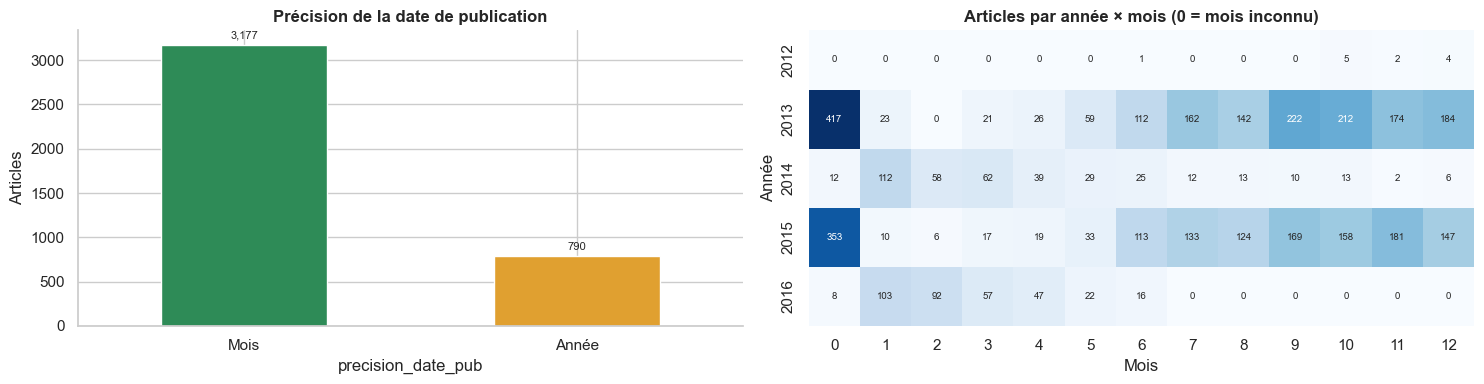

In [72]:
MONTHS = {m: i for i, m in enumerate(["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], 1)}
SEASONS = {"winter": 1, "spring": 4, "summer": 7, "autumn": 10, "fall": 10}
def mnum(x):
    if not isinstance(x, str): return np.nan
    x = x.strip()
    if x.isdigit(): return int(x) if 1 <= int(x) <= 12 else np.nan
    return MONTHS.get(x[:3].lower(), np.nan)

y = pd.to_numeric(a.pub_annee_src, errors="coerce"); m = a.pub_mois_src.map(mnum); src = pd.Series("PubDate", index=a.index)
ml = a.pub_medline_src.str.extract(r"^(\d{4})(?:\s+([A-Za-z]{3,}))?")
use_ml = y.isna() & ml[0].notna()
y = y.where(~use_ml, pd.to_numeric(ml[0], errors="coerce")); m = m.where(~use_ml, ml[1].map(mnum)); src[use_ml] = "MedlineDate"
sais = a.pub_saison_src.str.lower().map(SEASONS); use_s = m.isna() & sais.notna(); m = m.where(~use_s, sais); src[use_s & (src == "PubDate")] = "Saison"
rule("R10", "article", "annee_pub/mois_pub", "Date issue du texte libre MedlineDate (« 2016 Jan-Feb » → 2016, mois 1)", use_ml.sum(), len(a))
rule("R11", "article", "mois_pub", "Mois textuel (Aug…) converti en numérique ; saison → 1ᵉʳ mois de la saison", int(a.pub_mois_src.notna().sum() - a.pub_mois_src.str.isdigit().sum()) + int(use_s.sum()), len(a))
out_y = y.notna() & ((y < PARAMS["ANNEE_MIN"]) | (y > PARAMS["ANNEE_MAX"]))
rule("R12", "article", "annee_pub", f"Année hors [{PARAMS['ANNEE_MIN']}, {PARAMS['ANNEE_MAX']}] → NULL", out_y.sum(), y.notna().sum()); y[out_y] = np.nan; m[out_y] = np.nan
a["annee_pub"] = y.astype("Int64"); a["mois_pub"] = m.astype("Int64"); a["source_date_pub"] = src
a["precision_date_pub"] = np.where(a.annee_pub.isna(), "Inconnue", np.where(a.mois_pub.isna(), "Année", "Mois"))
dc = pd.to_datetime(a.date_creation_src, errors="coerce"); bad_dc = a.date_creation_src.notna() & dc.isna() | (dc.notna() & ((dc.dt.year < PARAMS["ANNEE_MIN"]) | (dc.dt.year > PARAMS["ANNEE_MAX"])))
rule("R13", "article", "date_creation", "Date de création invalide → NULL", bad_dc.sum(), a.date_creation_src.notna().sum()); dc[bad_dc] = pd.NaT; a["date_creation"] = dc.dt.date
print(f"Précision de la date de publication : {a.precision_date_pub.value_counts().to_dict()} · source : {a.source_date_pub.value_counts().to_dict()}")
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
a.precision_date_pub.value_counts().plot.bar(color=[C["ok"], C["warn"], C["bad"]][:a.precision_date_pub.nunique()], ax=ax[0], rot=0); show_bar_labels(ax[0]); ax[0].set(title="Précision de la date de publication", ylabel="Articles")
ct = pd.crosstab(a.annee_pub, a.mois_pub.fillna(0).astype(int)); sns.heatmap(ct, cmap="Blues", annot=True, fmt="d", annot_kws={"size": 7}, cbar=False, ax=ax[1]); ax[1].set(title="Articles par année × mois (0 = mois inconnu)", xlabel="Mois", ylabel="Année")
plt.tight_layout(); plt.show()

---
# T5 — Titre et résumé
**R14–R17.** Le titre est conservé **nettoyé** (balises `<i>`, entités `&amp;`, espaces). Le résumé est **conservé mais raccourci par NLP** (décision 5) : méthode **extractive** — on garde les phrases les plus représentatives du résumé, sans rien réécrire, donc sans risque d'invention.

**Méthode (R16b)** : découpage en phrases (étiquettes `BACKGROUND:`, `METHODS:`… retirées) → vecteurs **TF-IDF** (l'IDF est calculé sur tout le corpus, ce qui écarte automatiquement les mots vides, quelle que soit la langue) → graphe de similarité cosinus entre phrases → score **TextRank** (PageRank) avec un léger bonus pour la première et la dernière phrase (objectif / conclusion) → on garde la 1ʳᵉ phrase (objectif, si elle n'est pas trop longue) puis les meilleures phrases dans la limite `RESUME_MAX_CAR` caractères et `RESUME_MAX_PHRASES` phrases, **dans l'ordre d'origine**. Déterministe (aucun aléa).


In [73]:
t0 = a.titre.copy(); a["titre"] = clean_text(a.titre)
rule("R14", "article", "titre", "Titre : balises HTML, entités, espaces/caractères invisibles nettoyés", changed(t0, a.titre), len(a))
a["titre_traduit"] = a.titre.str.startswith("[") & a.titre.str.contains(r"\]\.?$")
a["titre"] = a.titre.str.replace(r"^\[(.+)\]\.?$", r"\1", regex=True)
rule("R15", "article", "titre", "Titres traduits « [Titre] » : crochets retirés, indicateur titre_traduit conservé", a.titre_traduit.sum(), len(a))

# --- Résumé : indicateurs (sur le texte d'origine) puis version courte par NLP extractif ---------------
from sklearn.feature_extraction.text import TfidfVectorizer
a["a_resume"] = a.resume_src.notna() & (a.resume_src.str.strip() != "")
a["mots_resume"] = a.resume_src.fillna("").str.split().str.len().where(a.a_resume, 0).astype(int)

LABEL_RX = re.compile(r"(?:^|\n)\s*[A-ZÀ-Ý][A-ZÀ-Ý0-9 /&,\-]{2,45}:\s*")          # « BACKGROUND: », « METHODS: »…
SENT_RX = re.compile(r"(?<=[.!?])\s+(?=[A-ZÀ-Ý0-9(\[\"“])")
ABBR = ["e.g.", "i.e.", "vs.", "et al.", "approx.", "Fig.", "Figs.", "Dr.", "No.", "ca.", "cf.", "Inc.", "Ltd."]
def phrases(txt):
    for ab in ABBR: txt = txt.replace(ab, ab.replace(".", "§"))
    out = []
    for bloc in txt.split("¶"):
        out += [p.replace("§", ".").strip() for p in SENT_RX.split(bloc) if p.strip()]
    return out
res_clean = clean_text(a.resume_src.fillna("").str.replace(LABEL_RX, "¶", regex=True).str.replace("\n", "¶", regex=False))
res_txt = res_clean.str.replace("¶", " ").str.replace(r"\s+", " ", regex=True).str.strip()      # texte nettoyé lisible (pour les statistiques et l'affichage)
docs = {i: phrases(t) for i, t in res_clean.items() if isinstance(t, str) and t}
tfidf = TfidfVectorizer(token_pattern=r"(?u)\b[^\W\d_]{3,}\b", sublinear_tf=True).fit([s for L in docs.values() for s in L])
MAXC, MAXP = PARAMS["RESUME_MAX_CAR"], PARAMS["RESUME_MAX_PHRASES"]
def coupe(t): return t[:MAXC].rsplit(" ", 1)[0].rstrip(",;:") + "…"
def resume_court(sents):
    full = " ".join(sents)
    if len(full) <= MAXC: return full                      # déjà court : inchangé
    n = len(sents)
    if n == 1: return coupe(full)
    X = tfidf.transform(sents); Wm = (X @ X.T).toarray(); np.fill_diagonal(Wm, 0)
    deg = Wm.sum(axis=1, keepdims=True); P = np.divide(Wm, deg, out=np.zeros_like(Wm), where=deg > 0)
    s = np.full(n, 1 / n)
    for _ in range(50): s = 0.15 / n + 0.85 * (P.T @ s)                                  # TextRank
    s = s * (1 + 0.3 * (np.arange(n) == 0) + 0.3 * (np.arange(n) == n - 1))              # objectif / conclusion
    chosen, total = [], 0
    ordre = [int(i) for i in np.argsort(-s, kind="stable")]
    if len(sents[0]) <= 0.6 * MAXC: ordre = [0] + [i for i in ordre if i != 0]          # la 1ʳᵉ phrase (objectif) est gardée si elle laisse de la place
    for i in ordre:
        L = len(sents[i]) + (1 if chosen else 0)
        if len(chosen) < MAXP and total + L <= MAXC: chosen.append(int(i)); total += L
    if not chosen: return coupe(sents[int(np.argmax(s))])                                # meilleure phrase trop longue
    return " ".join(sents[i] for i in sorted(chosen))
a["resume_court"] = pd.Series({i: resume_court(L) for i, L in docs.items()}).reindex(a.index)
a.loc[~a.a_resume, "resume_court"] = pd.NA
raccourci = a.resume_court.notna() & (a.resume_court.str.len() < res_txt.str.len() - 5)
rule("R16", "article", "resume", "Résumé : indicateurs a_resume / mots_resume calculés sur le texte d'origine", a.a_resume.sum(), len(a))
rule("R16b", "article", "resume_court", f"Résumé raccourci par NLP extractif (TF-IDF + TextRank, ≤ {MAXC} caractères, ≤ {MAXP} phrases)", raccourci.sum(), a.a_resume.sum())
a = a.drop(columns=["resume_src"])
a["mots_titre"] = a.titre.str.split().str.len()
a["doi"] = a.doi_brut.str.strip().str.lower().str.replace(r"^(https?://(dx\.)?doi\.org/|doi:\s*)", "", regex=True)
bad_doi = a.doi.notna() & ~a.doi.fillna("").str.fullmatch(r"10\.\d{4,9}/\S+"); rule("R17", "article", "doi", "DOI normalisé (minuscules, sans préfixe URL) ; format invalide → NULL", int(bad_doi.sum() + (a.doi != a.doi_brut.str.strip()).sum()), a.doi_brut.notna().sum()); a.loc[bad_doi, "doi"] = pd.NA
lo, lc = res_txt[a.a_resume].str.len(), a.resume_court.dropna().str.len()
print(f"Titres traduits : {a.titre_traduit.sum()} · articles avec résumé : {a.a_resume.sum()} ({pct(a.a_resume.sum(), len(a))} %) · DOI valides : {a.doi.notna().sum()} ({pct(a.doi.notna().sum(), len(a))} %)")
print(f"Résumé court : {raccourci.sum()} résumés raccourcis · longueur moyenne {lo.mean():.0f} → {lc.mean():.0f} caractères (−{100 * (1 - lc.mean() / lo.mean()):.0f} %) · max {lc.max()}")
for i in a[raccourci].index[:2]: print(f"\n— PMID {a.at[i, 'pmid']}\n  AVANT ({len(res_txt[i])} car.) : {res_txt[i][:300]}…\n  APRÈS ({len(a.at[i, 'resume_court'])} car.) : {a.at[i, 'resume_court']}")


Titres traduits : 164 · articles avec résumé : 3955 (99.7 %) · DOI valides : 3599 (90.7 %)
Résumé court : 3914 résumés raccourcis · longueur moyenne 1514 → 355 caractères (−77 %) · max 400

— PMID 23643526
  AVANT (1928 car.) : DNA damage and reactive oxygen species (ROS) generated by ionizing radiation (IR) activate DNA damage response (DDR) and cytokine signaling pathways, including double strand break (DSB) repair and TGFß/Smad signaling pathway. Proteins assembled at IR-induced DSB sites can be visualized as foci, incl…
  APRÈS (378 car.) : DNA damage and reactive oxygen species (ROS) generated by ionizing radiation (IR) activate DNA damage response (DDR) and cytokine signaling pathways, including double strand break (DSB) repair and TGFß/Smad signaling pathway. Phospho-ATM (Ser1981) foci were found in both spontaneous and IR-induced MN in PC3 cells, displaying a much lower frequency compared to ?H2AX and Smad7.

— PMID 23643600
  AVANT (1887 car.) : We identified factors predictin

---
# T6 — Langues et types de publication
**R18–R21.** Langue : trim + minuscules. Types : **libellé canonique par UI** (corrige `JOURNAL ARTICLE` vs `Journal Article`). Un article multi-typé reçoit **une catégorie principale** (règle de priorité) *en plus* de ses types détaillés (table de liaison).

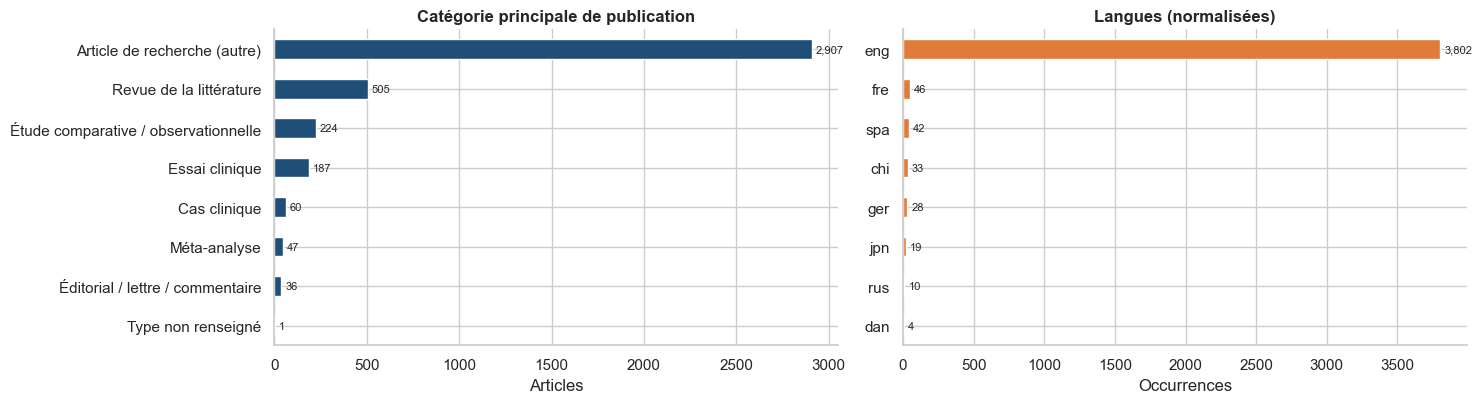

Types distincts : 38 → 36 (par UI) · langues distinctes : 17 → 15


In [74]:
keys = set(zip(a.art_id, a.source_fichier))
def sel(t, df):
    return df[[(i, f) in keys for i, f in zip(df.art_id, df.fichier)]].merge(a[["art_id", "source_fichier", "pmid"]], left_on=["art_id", "fichier"], right_on=["art_id", "source_fichier"]).drop(columns=["source_fichier"])
lg = sel("langues", S["langues"]); l0 = lg.langue.copy(); lg["langue"] = lg.langue.str.strip().str.lower()
rule("R18", "langues", "langue", "Langue en minuscules/trim (ex. ENG → eng)", changed(l0, lg.langue), len(lg))
lg = lg.drop_duplicates(["pmid", "langue"]); lg["est_principale"] = ~lg.duplicated("pmid")
tp = sel("types", S["types_pub"]); n_tnoui = int(tp.ui.isna().sum())
t2u = tp.dropna(subset=["ui"]).assign(tl=lambda d: d.type.str.lower()).groupby("tl").ui.agg(lambda s: s.value_counts().index[0]); rec_t = tp.ui.isna() & tp.type.str.lower().map(t2u).notna()
tp.loc[rec_t, "ui"] = tp.loc[rec_t, "type"].str.lower().map(t2u)
rule("R18a", "types_pub", "ui", "UI de type manquant retrouvé via le libellé (insensible à la casse)", rec_t.sum(), n_tnoui)
rej_t = tp.ui.isna(); rule("R18b", "types_pub", "ui", "UI de type manquant et irrécupérable → ligne rejetée", rej_t.sum(), n_tnoui)
reject(tp[rej_t].assign(k=lambda d: d.pmid + "#" + d.type.fillna("?")), "k", "Type de publication sans UI", "types_pub"); tp = tp[~rej_t]
ui_label = tp.groupby("ui").type.agg(lambda s: s.value_counts().index[0])
t0 = tp.type.copy(); tp["type"] = tp.ui.map(ui_label).fillna(tp.type)
rule("R19", "types_pub", "type", "Libellé du type unifié par UI (libellé le plus fréquent)", changed(t0, tp.type), len(tp))
n0 = len(tp); tp = tp.drop_duplicates(["pmid", "ui"]); rule("R20", "types_pub", "(pmid, ui)", "Doublons article×type supprimés", n0 - len(tp), n0)
CAT = [("Essai clinique", r"clinical trial|randomized controlled trial|controlled clinical trial"), ("Méta-analyse", r"meta-analysis"), ("Revue de la littérature", r"^review$"),
       ("Cas clinique", r"case reports"), ("Éditorial / lettre / commentaire", r"editorial|letter|comment|news|interview|biography|historical article|published erratum|retraction"),
       ("Étude comparative / observationnelle", r"comparative study|multicenter study|observational study|evaluation studies|validation studies|twin study")]
def categorie(types):
    low = [t.lower() for t in types]
    for lab, rx in CAT:
        if any(re.search(rx, t) for t in low): return lab
    return "Article de recherche (autre)"
cat = tp.groupby("pmid").type.apply(lambda s: categorie(list(s)))
a["categorie_publication"] = a.pmid.map(cat).fillna("Type non renseigné")
rule("R21", "article", "categorie_publication", "Catégorie principale dérivée des types (règle de priorité documentée)", len(a), len(a))
a["langue_principale"] = a.pmid.map(lg[lg.est_principale].set_index("pmid").langue)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
a.categorie_publication.value_counts().sort_values().plot.barh(color=C["main"], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set(title="Catégorie principale de publication", xlabel="Articles", ylabel="")
lg.langue.value_counts().head(8).sort_values().plot.barh(color=C["accent"], ax=ax[1]); show_bar_labels(ax[1], horizontal=True); ax[1].set(title="Langues (normalisées)", xlabel="Occurrences", ylabel="")
plt.tight_layout(); plt.show()
print(f"Types distincts : {S['types_pub'].type.nunique()} → {tp.ui.nunique()} (par UI) · langues distinctes : {S['langues'].langue.nunique()} → {lg.langue.nunique()}")

---
# T7 — Thématique : descripteurs MeSH et mots-clés
**R22–R27.** MeSH : libellé **canonique par UI** (corrige le libellé altéré détecté à l'étape 1). Mots-clés : découpage des listes collées (`;`), normalisation, dédoublonnage par article, libellé d'affichage = graphie la plus fréquente.

In [75]:
ms = sel("mesh", S["mesh"]); n_noui = int(ms.ui.isna().sum())
l2u = ms.dropna(subset=["ui"]).groupby("descripteur").ui.agg(lambda s: s.value_counts().index[0]); rec_ui = ms.ui.isna() & ms.descripteur.map(l2u).notna()
ms.loc[rec_ui, "ui"] = ms.loc[rec_ui, "descripteur"].map(l2u)
rule("R22a", "mesh", "ui", "UI MeSH manquant retrouvé via le libellé (même libellé ↔ UI connu)", rec_ui.sum(), n_noui)
rej_ui = ms.ui.isna(); rule("R22b", "mesh", "ui", "UI MeSH manquant et irrécupérable → ligne rejetée", rej_ui.sum(), n_noui)
reject(ms[rej_ui].assign(k=lambda d: d.pmid + "#" + d.descripteur.fillna("?")), "k", "Descripteur MeSH sans UI", "mesh"); ms = ms[~rej_ui]
lab = ms.groupby("ui").descripteur.agg(lambda s: s.value_counts().index[0]); l0 = ms.descripteur.copy()
ms["descripteur"] = ms.ui.map(lab); rule("R22", "mesh", "descripteur", "Libellé MeSH unifié par UI (corrige les libellés altérés)", changed(l0, ms.descripteur), len(ms))
ms["descripteur"] = clean_text(ms.descripteur, tags=False); ms["majeur"] = ms.majeur.eq("Y")
n0 = len(ms); ms = ms.drop_duplicates(["pmid", "ui"]); rule("R23", "mesh", "(pmid, ui)", "Doublons article×descripteur supprimés", n0 - len(ms), n0)
ms["est_geographique"] = ms.type.eq("Geographic")
mesh_dim = ms.groupby("ui").agg(descripteur=("descripteur", "first"), est_geographique=("est_geographique", "max")).reset_index()

kw = sel("mots_cles", S["mots_cles"]); n0 = len(kw)
kw["mot_cle"] = clean_text(kw.mot_cle, tags=True)
kw["mot_cle"] = kw.mot_cle.str.split(";"); kw = kw.explode("mot_cle"); kw["mot_cle"] = clean_text(kw.mot_cle.astype("string"), tags=False)
rule("R24", "mots_cles", "mot_cle", "Listes de mots-clés collées (séparateur « ; ») éclatées en lignes", len(kw) - n0, n0)
kw = kw[kw.mot_cle.notna() & (kw.mot_cle.str.len() >= 2)]
kw["cle"] = kw.mot_cle.str.lower().str.replace(r"[\s\.\-]+$", "", regex=True).str.replace(r"\s+", " ", regex=True)
kw = kw[kw.cle.str.len() >= 2]
lib = kw.groupby("cle").mot_cle.agg(lambda s: s.value_counts().index[0]); n_raw = kw.mot_cle.nunique(); n0 = len(kw)
kw = kw.drop_duplicates(["pmid", "cle"]); rule("R25", "mots_cles", "(pmid, clé)", "Doublons article×mot-clé (insensible à la casse) supprimés", n0 - len(kw), n0)
rule("R26", "mots_cles", "mot_cle", "Mots-clés fusionnés par clé normalisée (casse/ponctuation finale)", n_raw - kw.cle.nunique(), n_raw)
motcle_dim = kw.groupby("cle").agg(nb_publications=("pmid", "nunique")).reset_index(); motcle_dim["libelle"] = motcle_dim.cle.map(lib)
print(f"MeSH : {len(S['mesh']):,} → {len(ms):,} lignes · {mesh_dim.shape[0]:,} descripteurs · mots-clés : {n_raw:,} graphies → {motcle_dim.shape[0]:,} clés")
motcle_dim.sort_values("nb_publications", ascending=False).head(8)

MeSH : 36,034 → 36,032 lignes · 3,937 descripteurs · mots-clés : 7,308 graphies → 6,545 clés


,cle,nb_publications,libelle
4804,prostate cancer,1033,prostate cancer
795,cancer,133,cancer
4798,prostate,132,prostate
4915,prostatic neoplasms,104,prostatic neoplasms
5099,radical prostatectomy,87,radical prostatectomy
4959,psa,70,PSA
5129,radiotherapy,68,radiotherapy
4897,prostatectomy,66,prostatectomy


---
# T8 — Auteurs (personnes **et** auteurs collectifs)
**R28–R32.** Un nom n'est pas un identifiant (étape 1) : la clé d'un auteur individuel est `nom normalisé (sans accent, minuscules) | initiales`. Les **auteurs collectifs** (consortiums, groupes d'étude) **ne sont plus écartés** : ils entrent dans `auteur_dim` avec la clé `collectif | nom normalisé`, et la colonne **`type_auteur`** (`Individuel` / `Collectif`) permet de les distinguer ou de les isoler dans les analyses.


In [76]:
au = sel("auteurs", S["auteurs"]); n0 = len(au)
for c in ["nom", "prenom", "initiales", "collectif"]: au[c] = clean_text(au[c], tags=False)
au["initiales"] = au.initiales.str.upper().str.replace(r"[^A-ZÀ-Ý]", "", regex=True)
rule("R28", "auteurs", "nom/prénom/initiales", "Trim, espaces multiples, initiales en majuscules sans ponctuation", int((S["auteurs"][["nom", "prenom", "initiales"]].fillna("").sum(axis=1) != au[["nom", "prenom", "initiales"]].fillna("").sum(axis=1)).sum()) if len(au) == len(S["auteurs"]) else 0, n0)
au["est_collectif"] = au.nom.isna() & au.collectif.notna()
au["cle"] = np.where(au.est_collectif, "collectif|" + au.collectif.map(fold).fillna(""), au.nom.map(fold).fillna("") + "|" + au.initiales.fillna(""))
au["orcid_n"] = au.orcid.str.replace(r"^https?://orcid\.org/", "", regex=True).str.replace("-", "", regex=False).str.upper()
good = au.orcid_n.fillna("").str.fullmatch(r"\d{15}[\dX]"); au["orcid_n"] = np.where(good, au.orcid_n.str[:4] + "-" + au.orcid_n.str[4:8] + "-" + au.orcid_n.str[8:12] + "-" + au.orcid_n.str[12:], None)
rule("R29", "auteurs", "orcid", "ORCID normalisé au format xxxx-xxxx-xxxx-xxxx (16 chiffres sans tirets reformatés ; invalide → NULL)", int((au.orcid.notna() & (au.orcid != au.orcid_n)).sum()), int(au.orcid.notna().sum()))
sans_nom = (~au.est_collectif & (au.nom.isna() | (au.cle == "|"))) | (au.est_collectif & (au.cle == "collectif|"))      # collectif réduit à un tiret, etc.
rule("R30", "auteurs", "nom", "Auteur (individuel ou collectif) sans nom exploitable → ligne rejetée", sans_nom.sum(), len(au)); reject(au[sans_nom].assign(k=lambda d: d.pmid + "#" + d.rang.astype(str)), "k", "Auteur sans nom", "auteurs"); au = au[~sans_nom]
au = au.sort_values(["pmid", "rang"]); dup = au.duplicated(["pmid", "cle"]); n_d = int(dup.sum())
au = au[~dup]; rule("R31", "auteurs", "(pmid, clé)", "Même auteur (individuel ou collectif) répété dans une notice → 1 seule ligne (rang du 1ᵉʳ)", n_d, n0)
au["rang_src"] = au.rang; au["rang"] = au.groupby("pmid").cumcount() + 1; nmax = au.groupby("pmid").rang.transform("max"); au["est_premier"] = au.rang == 1; au["est_dernier"] = (au.rang == nmax) & (nmax > 1)
rule("R32b", "auteurs", "type_auteur", "Auteurs collectifs conservés dans auteur_dim (type_auteur = « Collectif ») au lieu d'être exclus", int(au.est_collectif.sum()), len(au))
ind = au[~au.est_collectif]; col = au[au.est_collectif]
auteur_ind = ind.groupby("cle").agg(nom=("nom", lambda s: s.value_counts().index[0]), initiales=("initiales", "first"), prenom_frequent=("prenom", lambda s: s.dropna().value_counts().index[0] if s.notna().any() else pd.NA),
                                    nb_prenoms_distincts=("prenom", lambda s: s.dropna().str.lower().nunique()), orcid=("orcid_n", lambda s: s.dropna().iloc[0] if s.notna().any() else pd.NA), nb_publications=("pmid", "nunique")).reset_index()
auteur_ind["type_auteur"] = "Individuel"
auteur_col = col.groupby("cle").agg(nom=("collectif", lambda s: s.value_counts().index[0]), nb_publications=("pmid", "nunique")).reset_index(); auteur_col["type_auteur"] = "Collectif"
auteur_dim = pd.concat([auteur_ind, auteur_col], ignore_index=True)[["cle", "type_auteur", "nom", "prenom_frequent", "initiales", "orcid", "nb_prenoms_distincts", "nb_publications"]]
rule("R32", "auteurs", "cle", "Clé d'auteur individuel = nom normalisé|initiales (homonymes potentiels signalés par nb_prenoms_distincts > 1)", int((auteur_ind.nb_prenoms_distincts > 1).sum()), len(auteur_ind))
print(f"Lignes auteur×article : {n0:,} → {len(au):,} · auteurs distincts : {len(auteur_dim):,} (individuels {len(auteur_ind):,} + collectifs {len(auteur_col):,}) · lignes collectives : {int(au.est_collectif.sum())} · clés individuelles à ≥ 2 prénoms (homonymes possibles) : {(auteur_ind.nb_prenoms_distincts > 1).sum()} ({pct((auteur_ind.nb_prenoms_distincts > 1).sum(), len(auteur_ind))} %)")
auteur_dim.sort_values("nb_publications", ascending=False).head(6)


Lignes auteur×article : 29,336 → 29,296 · auteurs distincts : 20,464 (individuels 20,405 + collectifs 59) · lignes collectives : 68 · clés individuelles à ≥ 2 prénoms (homonymes possibles) : 1727 (8.5 %)


,cle,type_auteur,nom,prenom_frequent,initiales,orcid,nb_prenoms_distincts,nb_publications
18917,wang|Y,Individuel,Wang,Yuzhuo,Y,<NA>,23.00,40
18875,wang|J,Individuel,Wang,Jingcheng,J,<NA>,26.00,33
10437,li|J,Individuel,Li,Jing,J,<NA>,16.00,31
18926,wang|Z,Individuel,Wang,Zhong,Z,<NA>,18.00,28
18871,wang|H,Individuel,Wang,He,H,<NA>,20.00,28
6219,graefen|M,Individuel,Graefen,Markus,M,<NA>,2.00,28


---
# T9 — Affiliations → **pays** (dimension géographique)
**R33–R34.** L'affiliation (texte libre) n'est conservée que pour en **extraire le pays** (décision 7). Les règles d'extraction de l'étape 1 sont reprises et **enrichies** à partir des segments non résolus.

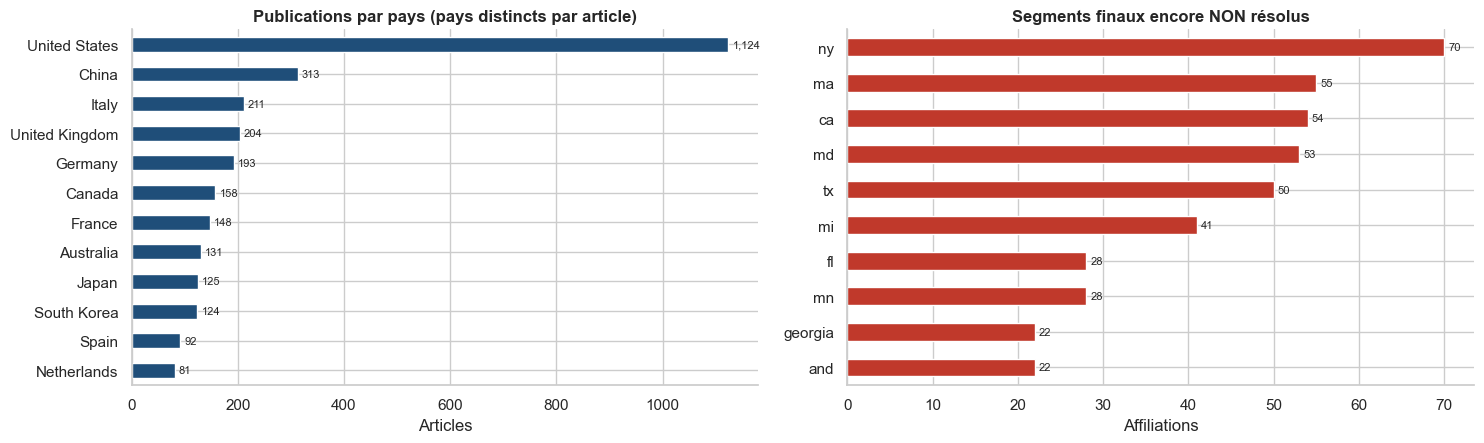

Pays résolus : 83.4 % des affiliations · articles avec ≥ 1 pays : 2,990 (75.4 %) · pays distincts : 71


In [77]:
COUNTRIES = {"United States": ["usa", "u.s.a", "u.s.a.", "us", "united states", "united states of america", "u.s."], "United Kingdom": ["uk", "u.k.", "united kingdom", "england", "scotland", "wales", "northern ireland", "great britain"],
 "China": ["china", "p.r. china", "pr china", "people's republic of china", "p. r. china", "p.r.china", "peoples r china", "pr of china", "p r china"], "Hong Kong": ["hong kong", "hong kong sar"], "Taiwan": ["taiwan", "republic of china", "roc"],
 "Germany": ["germany", "deutschland"], "France": ["france"], "Italy": ["italy", "italia"], "Spain": ["spain", "españa"], "Japan": ["japan"], "Canada": ["canada"], "Australia": ["australia"], "Netherlands": ["the netherlands", "netherlands", "holland"],
 "Switzerland": ["switzerland"], "Sweden": ["sweden"], "Denmark": ["denmark"], "Norway": ["norway"], "Finland": ["finland"], "Belgium": ["belgium"], "Austria": ["austria"], "South Korea": ["korea", "south korea", "republic of korea", "republic of  korea"],
 "India": ["india"], "Brazil": ["brazil", "brasil"], "Turkey": ["turkey", "türkiye"], "Israel": ["israel"], "Greece": ["greece"], "Poland": ["poland"], "Portugal": ["portugal"], "Ireland": ["ireland"], "Iran": ["iran", "islamic republic of iran"],
 "Egypt": ["egypt"], "Mexico": ["mexico", "méxico"], "Russia": ["russia", "russian federation"], "Singapore": ["singapore"], "Saudi Arabia": ["saudi arabia"], "Czech Republic": ["czech republic", "czechia"], "Hungary": ["hungary"],
 "Argentina": ["argentina"], "Chile": ["chile"], "South Africa": ["south africa"], "New Zealand": ["new zealand"], "Thailand": ["thailand"], "Pakistan": ["pakistan"], "Tunisia": ["tunisia"], "Morocco": ["morocco"], "Lebanon": ["lebanon"],
 "Malaysia": ["malaysia"], "Romania": ["romania"], "Serbia": ["serbia"], "Croatia": ["croatia"], "Slovenia": ["slovenia"], "Ukraine": ["ukraine"], "Colombia": ["colombia"], "Cuba": ["cuba"], "Peru": ["peru"], "Venezuela": ["venezuela"],
 "Bulgaria": ["bulgaria"], "Slovakia": ["slovakia"], "Lithuania": ["lithuania"], "Estonia": ["estonia"], "Iceland": ["iceland"], "Luxembourg": ["luxembourg"], "Kuwait": ["kuwait"], "Qatar": ["qatar"], "United Arab Emirates": ["united arab emirates", "uae"],
 "Jordan": ["jordan"], "Iraq": ["iraq"], "Nigeria": ["nigeria"], "Kenya": ["kenya"], "Ghana": ["ghana"], "Uganda": ["uganda"], "Bangladesh": ["bangladesh"], "Sri Lanka": ["sri lanka"], "Vietnam": ["vietnam", "viet nam"], "Indonesia": ["indonesia"], "Philippines": ["philippines"], "Nepal": ["nepal"]}
ALIAS = {x: c for c, al in COUNTRIES.items() for x in al}
US_STATES = {"alabama", "alaska", "arizona", "arkansas", "california", "colorado", "connecticut", "delaware", "florida", "hawaii", "idaho", "illinois", "indiana", "iowa", "kansas", "kentucky", "louisiana", "maine", "maryland",
             "massachusetts", "michigan", "minnesota", "mississippi", "missouri", "montana", "nebraska", "nevada", "new hampshire", "new jersey", "new mexico", "new york", "north carolina", "north dakota", "ohio", "oklahoma",
             "oregon", "pennsylvania", "rhode island", "south carolina", "south dakota", "tennessee", "texas", "utah", "vermont", "virginia", "washington", "west virginia", "wisconsin", "wyoming"}   # « New Mexico » ≠ Mexique
US_ZIP = re.compile(r"\b[A-Z]{2}\s\d{5}(-\d{4})?\b")
def extract_country(txt):
    if not isinstance(txt, str): return None
    t = re.sub(r"(Electronic address|E-mail|Email)\s*:.*$", "", txt, flags=re.I).strip().rstrip(".; ")
    last = re.sub(r"^\W+|\W+$", "", t.split(",")[-1].strip().lower().rstrip("."))
    if last in US_STATES: return "United States"
    if last in ALIAS: return ALIAS[last]
    for al in sorted(ALIAS, key=len, reverse=True):
        if len(al) > 3 and t.lower().endswith(al): return ALIAS[al]
    if US_ZIP.search(t): return "United States"
    return None
af = sel("affils", S["affils"]); af["affiliation"] = clean_text(af.affiliation, tags=False)
uniq = pd.Series(af.affiliation.dropna().unique()); mp = dict(zip(uniq, uniq.map(extract_country))); af["pays"] = af.affiliation.map(mp)
rule("R33", "affils", "pays", "Pays extrait du texte d'affiliation (dictionnaire d'alias + motif code postal US + garde-fou noms d'États US)", af.pays.notna().sum(), len(af))
unres = af[af.pays.isna()].affiliation.str.rstrip(". ").str.split(",").str[-1].str.strip().str.lower().value_counts().head(10)
pub_pays = af.dropna(subset=["pays"]).drop_duplicates(["pmid", "pays"])[["pmid", "pays"]]
fa = af[af.rang_auteur == 1].sort_values(["pmid", "rang_aff"]).dropna(subset=["pays"]).drop_duplicates("pmid").set_index("pmid").pays
a["pays_premier_auteur"] = a.pmid.map(fa)
rule("R34", "article", "pays_premier_auteur", "Pays de la 1ʳᵉ affiliation du 1ᵉʳ auteur", a.pays_premier_auteur.notna().sum(), len(a))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
pub_pays.pays.value_counts().head(12).sort_values().plot.barh(color=C["main"], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set(title="Publications par pays (pays distincts par article)", xlabel="Articles", ylabel="")
unres.sort_values().plot.barh(color=C["bad"], ax=ax[1]); show_bar_labels(ax[1], horizontal=True); ax[1].set(title="Segments finaux encore NON résolus", xlabel="Affiliations", ylabel="")
plt.tight_layout(); plt.show()
print(f"Pays résolus : {pct(af.pays.notna().sum(), len(af))} % des affiliations · articles avec ≥ 1 pays : {pub_pays.pmid.nunique():,} ({pct(pub_pays.pmid.nunique(), len(a))} %) · pays distincts : {pub_pays.pays.nunique()}")

---
# T9b — Substances chimiques et institutions (axes 3 et 4 du cahier des charges)
**R36–R40.** *Substances* : libellé canonique par UI, doublons article×substance retirés. *Institutions* : l'affiliation est du texte libre (souvent plusieurs affiliations séparées par `;`). On extrait **l'institution** par une règle heuristique et documentée : parmi les segments séparés par des virgules (hors « Department… »), on retient le premier segment contenant *university* (sinon *hospital / clinic*, sinon *institute / center / school…*), à défaut le premier segment. Chaque institution reçoit le pays de ses affiliations, ce qui fait de `pays_dim` une **sous-dimension** d'`institution_dim`.


In [78]:
chim = sel("chimie", S["chimie"]); n0 = len(chim)
chim["substance"] = clean_text(chim.substance, tags=False); chim["registre"] = chim.registre.str.strip().where(lambda s: s != "0")
no_ui = chim.ui.isna(); rule("R36", "chimie", "ui", "Substance sans UI → ligne rejetée", no_ui.sum(), n0)
reject(chim[no_ui].assign(k=lambda d: d.pmid + "#" + d.substance.fillna("?")), "k", "Substance sans UI", "chimie"); chim = chim[~no_ui]
lab_s = chim.groupby("ui").substance.agg(lambda s: s.value_counts().index[0]); s0 = chim.substance.copy(); chim["substance"] = chim.ui.map(lab_s)
n1 = len(chim); chim = chim.drop_duplicates(["pmid", "ui"]); rule("R37", "chimie", "(pmid, ui)", "Doublons article×substance supprimés ; libellé unifié par UI", n1 - len(chim) + changed(s0, chim.substance), n1)
substance_dim = chim.groupby("ui").agg(substance=("substance", "first"), registre=("registre", mode_), nb_publications=("pmid", "nunique")).reset_index()

GRP = [re.compile(p, re.I) for p in [r"universit|université|universidad|universität|università|univ\.", r"hospital|hôpital|clinic|medical cent|klinik", r"institut|center|centre|laborator|academy|foundation|college|school|cancer"]]
def institution(chunk):
    segs = [s.strip() for s in re.sub(r"(Electronic address|E-mail|Email)\s*:.*$", "", chunk, flags=re.I).split(",") if s.strip()]
    segs = [s for s in segs if not re.match(r"(department|dept|division|service|unit)\b", s, re.I)] or segs
    for rx in GRP:
        for s in segs:
            if rx.search(s): return s
    return segs[0] if segs else None
ac = af.dropna(subset=["affiliation"])[["pmid", "rang_auteur", "affiliation"]].copy()
ac["chunk"] = ac.affiliation.str.split(";"); ac = ac.explode("chunk"); ac["chunk"] = ac.chunk.str.strip(); ac = ac[ac.chunk.str.len() > 3]
uq = pd.Series(ac.chunk.unique()); ac["institution"] = ac.chunk.map(dict(zip(uq, uq.map(institution)))); ac["pays"] = ac.chunk.map(dict(zip(uq, uq.map(extract_country))))
ac["cle_institution"] = ac.institution.map(fold); n_ac = len(ac)
ac = ac[ac.cle_institution.notna() & (ac.cle_institution.str.len() >= 3)]
rule("R38", "affils", "institution", "Institution extraite du texte d'affiliation (règle heuristique : université > hôpital > institut/centre)", len(ac), n_ac)
lk = ac.merge(au[["pmid", "rang_src", "cle"]], left_on=["pmid", "rang_auteur"], right_on=["pmid", "rang_src"], how="left")
rule("R39", "affils", "auteur", "Affiliation d'un auteur écarté (doublon ou sans nom) → lien auteur×institution non retenu", int(lk.cle.isna().sum()), len(lk))
inst_links = lk.dropna(subset=["cle"]).drop_duplicates(["pmid", "cle", "cle_institution"])[["pmid", "cle", "cle_institution"]]
ac_ok = ac.merge(inst_links[["pmid", "cle_institution"]].drop_duplicates(), on=["pmid", "cle_institution"])
institution_dim = ac_ok.groupby("cle_institution").agg(libelle=("institution", mode_), pays=("pays", lambda s: s.dropna().value_counts().index[0] if s.notna().any() else pd.NA), nb_publications=("pmid", "nunique")).reset_index()
rule("R40", "affils", "institution", "Institutions distinctes après normalisation (clé = nom sans accent ni ponctuation)", len(institution_dim), ac_ok.institution.nunique())
print(f"Substances : {len(chim):,} lignes · {len(substance_dim):,} substances · articles concernés : {chim.pmid.nunique():,}")
print(f"Institutions : {len(institution_dim):,} · liens article×auteur×institution : {len(inst_links):,} · institutions avec pays : {pct(institution_dim.pays.notna().sum(), len(institution_dim))} %")
institution_dim.sort_values("nb_publications", ascending=False).head(8)


Substances : 8,253 lignes · 2,594 substances · articles concernés : 1,864
Institutions : 4,809 · liens article×auteur×institution : 18,832 · institutions avec pays : 81.7 %


,cle_institution,libelle,pays,nb_publications
4124,university of california,University of California,United States,59
2413,memorial sloan kettering cancer center,Memorial Sloan Kettering Cancer Center,United States,56
2513,national cancer institute,National Cancer Institute,United States,44
4288,university of michigan,University of Michigan,United States,42
4515,university of washington,University of Washington,United States,34
4472,university of toronto,University of Toronto,Canada,33
4114,university of british columbia,University of British Columbia,Canada,31
2339,mayo clinic,Mayo Clinic,United States,29


---
# T10 — Assemblage de la table large intermédiaire et mesures dérivées
`article_large` est une table **de travail** (non exportée) qui regroupe tout ce qui concerne un article. Elle est **découpée à l'étape T11** : le texte part dans les dimensions, seules les clés étrangères et les mesures restent dans la table de faits `article_fact`.
Les compteurs (`nb_auteurs`, `nb_mesh`…) sont **recalculés à partir des tables propres** (et non recopiés de la source) : ils sont donc cohérents avec les tables de liaison qui seront chargées. `nb_auteurs` compte désormais les auteurs **individuels et collectifs**.


In [79]:
a["statut_citation"] = clean_text(a.statut_citation, tags=False)
cnt = lambda df, col="pmid": df.groupby(col).size()
a["nb_auteurs"] = a.pmid.map(cnt(au)).fillna(0).astype(int); a["nb_collectifs"] = a.pmid.map(cnt(au[au.est_collectif])).fillna(0).astype(int)
a["nb_mesh"] = a.pmid.map(cnt(ms)).fillna(0).astype(int); a["nb_mesh_majeurs"] = a.pmid.map(cnt(ms[ms.majeur])).fillna(0).astype(int)
a["nb_mots_cles"] = a.pmid.map(cnt(kw)).fillna(0).astype(int); a["nb_pays"] = a.pmid.map(cnt(pub_pays)).fillna(0).astype(int)
a["nb_substances"] = a.pmid.map(cnt(chim)).fillna(0).astype(int); a["nb_institutions"] = a.pmid.map(inst_links.groupby("pmid").cle_institution.nunique()).fillna(0).astype(int)
a["est_indexe_mesh"] = a.nb_mesh > 0
COLS = ["pmid", "nlm_id", "titre", "titre_traduit", "mots_titre", "annee_pub", "mois_pub", "precision_date_pub", "source_date_pub", "date_creation", "categorie_publication", "langue_principale",
        "statut_citation", "doi", "resume_court", "a_resume", "mots_resume", "nb_auteurs", "nb_collectifs", "nb_mesh", "nb_mesh_majeurs", "nb_mots_cles", "nb_pays", "nb_substances", "nb_institutions", "pays_premier_auteur", "est_indexe_mesh", "source_fichier", "niveau_reparation"]
article_large = a[COLS].sort_values("pmid").reset_index(drop=True)
# écart de comptage avec le staging (explique les corrections) -------------------------------
ref = S["art"].dropna(subset=["pmid"]).drop_duplicates("pmid").set_index("pmid")
cmp_ = pd.DataFrame({"nb_auteurs (source)": pd.to_numeric(ref.n_auteurs).reindex(article_large.pmid).values, "nb_auteurs (transformé)": article_large.nb_auteurs.values})
print(f"Articles : {len(article_large):,} · articles dont nb_auteurs diffère de la source : {(cmp_.iloc[:,0] != cmp_.iloc[:,1]).sum()} (doublons d'auteurs retirés, auteurs sans nom rejetés)")
article_large.head(4).T


Articles : 3,967 · articles dont nb_auteurs diffère de la source : 40 (doublons d'auteurs retirés, auteurs sans nom rejetés)


,0,1,2,3
pmid,23643526,23643600,23643603,23643697
nlm_id,0400763,0376374,0376374,100885136
titre,Smad7 foci are present in micronuclei induced by heavy particle radiation.,Predictive factors of oncologic outcomes in patients who do not achieve unde...,Pathological outcomes in men with low risk and very low risk prostate cancer...,Differences in self-reported outcomes of open prostatectomy patients and rob...
titre_traduit,False,False,False,False
mots_titre,11,18,20,17
annee_pub,2013,2013,2013,2013
mois_pub,8,11,10,12
precision_date_pub,Mois,Mois,Mois,Mois
source_date_pub,PubDate,PubDate,PubDate,PubDate
date_creation,2013-09-16,2013-10-14,2013-09-13,2013-11-25


---
# T11 — Modèle en flocon : clés de substitution, dimensions, sous-dimensions et table de faits
Le modèle n'utilise que quatre types de tables : **table de faits**, **dimensions**, **sous-dimensions** et **tables de liaison**.

**Table de faits `article_fact`** (grain : *une ligne = une publication distincte*) : uniquement des **clés étrangères entières** et des **mesures** (aucune colonne textuelle).

| Type | Tables | Rôle |
|---|---|---|
| **Table de faits** | `article_fact` | 1 ligne par publication |
| **Dimensions** (reliées à la fait) | `article_dim`, `revue_dim`, `temps_dim` (2 rôles : publication, création), `categorie_dim`, `statut_dim`, `langue_dim`, `pays_dim` (pays du 1ᵉʳ auteur) | attributs descriptifs (titre, DOI, résumé court, revue…) |
| **Tables de liaison** (relations N-N de l'article ; `article_key` → `article_dim`) | `article_auteur_bridge`, `article_mesh_bridge`, `article_motcle_bridge`, `article_type_bridge`, `article_langue_bridge`, `article_pays_bridge`, `article_substance_bridge`, `article_institution_bridge` | un article peut être associé à plusieurs éléments ; ces tables portent les clés d'association et les attributs du lien, sans double comptage dans la table de faits |
| **Dimensions atteintes via les tables de liaison** | `auteur_dim` (individuels + collectifs), `mesh_dim`, `motcle_dim`, `type_publication_dim`, `substance_dim`, `institution_dim` | référentiels des relations N-N ci-dessus |
| **Sous-dimension** | `pays_dim` | en plus de son rôle de dimension, sous-dimension de `revue_dim` (pays de l'éditeur) et d'`institution_dim` (pays de l'institution) |

Chaque table reçoit une **clé de substitution entière déterministe** (rang de la clé métier triée) : relancer le notebook redonne les mêmes clés. Le membre `0` signifie « non renseigné ».


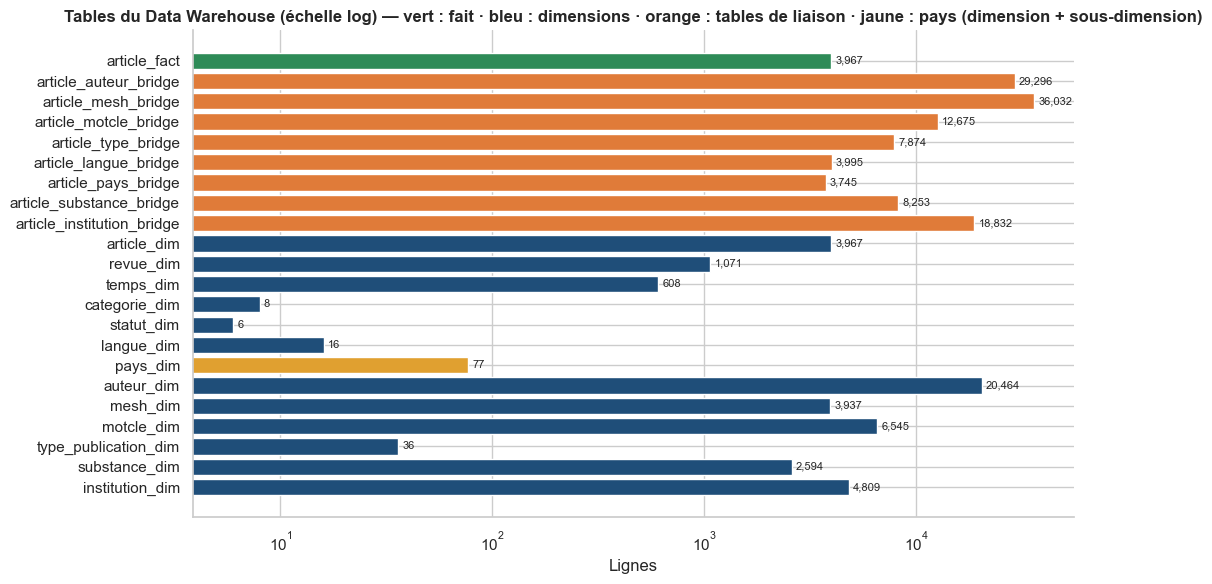

,lignes,colonnes,nature
article_fact,3967,19,Fait
article_auteur_bridge,29296,5,Table de liaison
article_mesh_bridge,36032,3,Table de liaison
article_motcle_bridge,12675,2,Table de liaison
article_type_bridge,7874,2,Table de liaison
article_langue_bridge,3995,3,Table de liaison
article_pays_bridge,3745,2,Table de liaison
article_substance_bridge,8253,2,Table de liaison
article_institution_bridge,18832,3,Table de liaison
article_dim,3967,11,Dimension


In [80]:
def add_sk(df, key, by, unknown=None, sort_key=None):
    """Ajoute une clé de substitution entière déterministe (tri sur la clé métier). `unknown` ajoute le membre 0 « non renseigné »."""
    d = df.sort_values(by, key=sort_key, kind="stable").reset_index(drop=True)
    d.insert(0, key, np.arange(1, len(d) + 1))
    if unknown is not None: d = pd.concat([pd.DataFrame([{key: 0, **unknown}]), d], ignore_index=True)
    return d
M = lambda d, bk, key: dict(zip(d[bk], d[key]))          # clé métier -> clé de substitution

LANG_LABEL = {"eng": "Anglais", "fre": "Français", "ger": "Allemand", "spa": "Espagnol", "ita": "Italien", "jpn": "Japonais", "chi": "Chinois", "por": "Portugais", "rus": "Russe", "pol": "Polonais", "dut": "Néerlandais",
              "swe": "Suédois", "dan": "Danois", "nor": "Norvégien", "fin": "Finnois", "kor": "Coréen", "heb": "Hébreu", "hun": "Hongrois", "cze": "Tchèque", "tur": "Turc", "gre": "Grec"}
lg = lg[lg.pmid.isin(article_large.pmid)]; tp = tp[tp.pmid.isin(article_large.pmid)]

# ── pays : un seul référentiel pour les affiliations ET pour le pays de l'éditeur de la revue (sous-dimension de revue_dim) ──
NLM_PAYS = {"England": "United Kingdom", "Scotland": "United Kingdom", "Wales": "United Kingdom", "Northern Ireland": "United Kingdom", "Korea (South)": "South Korea",
            "China (Republic : 1949- )": "Taiwan", "Russia (Federation)": "Russia", "Georgia (Republic)": "Georgia"}
revue["pays_editeur_n"] = revue.pays_editeur.map(lambda x: NLM_PAYS.get(str(x).strip(), str(x).strip()) if isinstance(x, str) else pd.NA)
rule("R35", "revue", "pays_editeur", "Pays de l'éditeur (nomenclature NLM : England, Korea (South), China (Republic : 1949- )…) aligné sur la nomenclature des pays des affiliations",
     int((revue.pays_editeur.notna() & (revue.pays_editeur != revue.pays_editeur_n)).sum()), int(revue.pays_editeur.notna().sum()))
pays_dim = add_sk(pd.DataFrame({"pays": sorted(set(pub_pays.pays) | set(revue.pays_editeur_n.dropna()) | set(institution_dim.pays.dropna()))}), "pays_key", "pays", unknown=dict(pays="Non renseigné"))

# ── dimensions ──
revue_dim = add_sk(revue.assign(pays_key=revue.pays_editeur_n.map(M(pays_dim, "pays", "pays_key")).fillna(0).astype(int))[["nlm_id", "titre", "abrev", "issn", "issn_liaison", "pays_key"]], "revue_key", "nlm_id")
MOIS_FR = ["Janvier", "Février", "Mars", "Avril", "Mai", "Juin", "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"]
y_, m_ = article_large.annee_pub.astype("Int64"), article_large.mois_pub.astype("Int64")
tk_pub = (y_.fillna(0) * 10000 + m_.fillna(0) * 100).astype(int)                       # AAAAMM00 : niveau mois (ou AAAA0000 : année seule)
dc_ = pd.to_datetime(article_large.date_creation); tk_cre = (dc_.dt.year * 10000 + dc_.dt.month * 100 + dc_.dt.day).fillna(0).astype(int)   # AAAAMMJJ
temps_dim = pd.DataFrame({"temps_key": sorted({0} | set(tk_pub) | set(tk_cre))})
temps_dim["annee"], temps_dim["mois"], temps_dim["jour"] = temps_dim.temps_key // 10000, temps_dim.temps_key // 100 % 100, temps_dim.temps_key % 100
temps_dim["niveau"] = np.select([temps_dim.annee == 0, temps_dim.mois == 0, temps_dim.jour == 0], ["Inconnu", "Année", "Mois"], "Jour")
for c_ in ["annee", "mois", "jour"]: temps_dim[c_] = temps_dim[c_].where(temps_dim[c_] > 0).astype("Int64")
temps_dim["libelle_mois"] = temps_dim.mois.map(lambda i: MOIS_FR[int(i) - 1] if pd.notna(i) else pd.NA); temps_dim["trimestre"] = ((temps_dim.mois - 1) // 3 + 1).astype("Int64")
categorie_dim = add_sk(pd.DataFrame({"categorie": sorted(article_large.categorie_publication.unique())}), "categorie_key", "categorie")
statut_dim = add_sk(pd.DataFrame({"statut_citation": sorted(article_large.statut_citation.dropna().unique())}), "statut_key", "statut_citation", unknown=dict(statut_citation="Non renseigné"))
langue_dim = pd.DataFrame({"code_langue": sorted(lg.langue.unique())}); langue_dim["libelle"] = langue_dim.code_langue.map(LANG_LABEL).fillna(langue_dim.code_langue)
langue_dim = add_sk(langue_dim, "langue_key", "code_langue", unknown=dict(code_langue="n/d", libelle="Non renseignée"))
type_dim = add_sk(tp.groupby("ui").type.first().reset_index().rename(columns={"ui": "ui_type", "type": "libelle"}), "type_key", "ui_type")
article_dim = add_sk(article_large[["pmid", "titre", "titre_traduit", "doi", "resume_court", "a_resume", "est_indexe_mesh", "source_date_pub", "source_fichier", "niveau_reparation"]], "article_key", "pmid", sort_key=lambda s: s.astype("int64"))
auteur_dim = add_sk(auteur_dim.rename(columns={"cle": "cle_auteur"}), "auteur_key", "cle_auteur")
mesh_dim = add_sk(mesh_dim.rename(columns={"ui": "ui_mesh"}), "mesh_key", "ui_mesh")
motcle_dim = add_sk(motcle_dim.rename(columns={"cle": "cle_motcle"})[["cle_motcle", "libelle", "nb_publications"]], "motcle_key", "cle_motcle")
substance_dim = add_sk(substance_dim.rename(columns={"ui": "ui_substance"}), "substance_key", "ui_substance")
institution_dim = add_sk(institution_dim.assign(pays_key=institution_dim.pays.map(M(pays_dim, "pays", "pays_key")).fillna(0).astype(int))[["cle_institution", "libelle", "pays_key", "nb_publications"]], "institution_key", "cle_institution")   # sous-dimension → pays_dim

# ── table de faits : clés étrangères + mesures uniquement ──
AL = article_large
article_fact = pd.DataFrame({
    "article_key": AL.pmid.map(M(article_dim, "pmid", "article_key")), "revue_key": AL.nlm_id.map(M(revue_dim, "nlm_id", "revue_key")),
    "temps_pub_key": tk_pub.values, "temps_creation_key": tk_cre.values,
    "categorie_key": AL.categorie_publication.map(M(categorie_dim, "categorie", "categorie_key")), "statut_key": AL.statut_citation.map(M(statut_dim, "statut_citation", "statut_key")).fillna(0),
    "langue_key": AL.langue_principale.map(M(langue_dim, "code_langue", "langue_key")).fillna(0), "pays_premier_auteur_key": AL.pays_premier_auteur.map(M(pays_dim, "pays", "pays_key")).fillna(0),
    "nb_publications": 1, "nb_auteurs": AL.nb_auteurs, "nb_collectifs": AL.nb_collectifs, "nb_mesh": AL.nb_mesh, "nb_mesh_majeurs": AL.nb_mesh_majeurs,
    "nb_mots_cles": AL.nb_mots_cles, "nb_pays": AL.nb_pays, "nb_substances": AL.nb_substances, "nb_institutions": AL.nb_institutions, "mots_titre": AL.mots_titre, "mots_resume": AL.mots_resume}).astype("int64").sort_values("article_key").reset_index(drop=True)

# ── faits d'association (relations N-N) : clés étrangères seulement ──
def fait_assoc(df, bk, dim, dim_bk, dim_key, fk, extra=(), tri=None):
    o = pd.DataFrame({"article_key": df.pmid.map(M(article_dim, "pmid", "article_key")).values, fk: df[bk].map(M(dim, dim_bk, dim_key)).values})
    for c_ in extra: o[c_] = df[c_].astype(int).values
    assert o.notna().all().all(), f"clé orpheline dans {fk}"
    return o.astype("int64").sort_values(tri or ["article_key", fk]).reset_index(drop=True)
article_auteur_bridge = fait_assoc(au, "cle", auteur_dim, "cle_auteur", "auteur_key", "auteur_key", ("rang", "est_premier", "est_dernier"), ["article_key", "rang"])
article_mesh_bridge = fait_assoc(ms, "ui", mesh_dim, "ui_mesh", "mesh_key", "mesh_key", ("majeur",))
article_motcle_bridge = fait_assoc(kw, "cle", motcle_dim, "cle_motcle", "motcle_key", "motcle_key")
article_type_bridge = fait_assoc(tp, "ui", type_dim, "ui_type", "type_key", "type_key")
article_langue_bridge = fait_assoc(lg, "langue", langue_dim, "code_langue", "langue_key", "langue_key", ("est_principale",))
article_pays_bridge = fait_assoc(pub_pays, "pays", pays_dim, "pays", "pays_key", "pays_key")
article_substance_bridge = fait_assoc(chim, "ui", substance_dim, "ui_substance", "substance_key", "substance_key")
il = inst_links.assign(article_key=inst_links.pmid.map(M(article_dim, "pmid", "article_key")), auteur_key=inst_links.cle.map(M(auteur_dim, "cle_auteur", "auteur_key")),
                       institution_key=inst_links.cle_institution.map(M(institution_dim, "cle_institution", "institution_key")))[["article_key", "auteur_key", "institution_key"]]
assert il.notna().all().all(), "clé orpheline dans article_institution"
article_institution_bridge = il.astype("int64").drop_duplicates().sort_values(["article_key", "auteur_key", "institution_key"]).reset_index(drop=True)   # collaborations auteur × institution

DW = {"article_fact": article_fact, "article_auteur_bridge": article_auteur_bridge, "article_mesh_bridge": article_mesh_bridge, "article_motcle_bridge": article_motcle_bridge,
      "article_type_bridge": article_type_bridge, "article_langue_bridge": article_langue_bridge, "article_pays_bridge": article_pays_bridge, "article_substance_bridge": article_substance_bridge, "article_institution_bridge": article_institution_bridge,
      "article_dim": article_dim, "revue_dim": revue_dim, "temps_dim": temps_dim, "categorie_dim": categorie_dim, "statut_dim": statut_dim, "langue_dim": langue_dim,
      "pays_dim": pays_dim, "auteur_dim": auteur_dim, "mesh_dim": mesh_dim, "motcle_dim": motcle_dim, "type_publication_dim": type_dim, "substance_dim": substance_dim, "institution_dim": institution_dim}
NATURE = {t: ("Fait" if t == "article_fact" else "Table de liaison" if t.endswith("_bridge") else "Dimension + sous-dimension" if t == "pays_dim" else "Dimension") for t in DW}
sizes = pd.DataFrame({"lignes": {k: len(v) for k, v in DW.items()}, "colonnes": {k: v.shape[1] for k, v in DW.items()}, "nature": NATURE})
fig, ax = plt.subplots(figsize=(11, 6)); s_ = sizes.iloc[::-1]
ax.barh(s_.index, s_.lignes, color=s_.nature.map({"Fait": C["ok"], "Table de liaison": C["accent"], "Dimension": C["main"], "Dimension + sous-dimension": C["warn"]})); ax.set_xscale("log"); show_bar_labels(ax, horizontal=True)
ax.set(title="Tables du Data Warehouse (échelle log) — vert : fait · bleu : dimensions · orange : tables de liaison · jaune : pays (dimension + sous-dimension)", xlabel="Lignes"); plt.tight_layout(); plt.show()
sizes


---
# T12 — Contrôles d'intégrité automatiques
Chaque contrôle est un `assert` : le notebook **échoue** si une règle d'intégrité est violée (et ne produit alors aucune sortie douteuse).

In [81]:
chk = []
def check(nom, cond, detail=""):
    chk.append(dict(contrôle=nom, résultat="✅ OK" if cond else "❌ ÉCHEC", détail=detail)); assert cond, f"Contrôle en échec : {nom} {detail}"
KEYS = {"article_dim": "article_key", "revue_dim": "revue_key", "temps_dim": "temps_key", "categorie_dim": "categorie_key", "statut_dim": "statut_key", "langue_dim": "langue_key",
        "pays_dim": "pays_key", "auteur_dim": "auteur_key", "mesh_dim": "mesh_key", "motcle_dim": "motcle_key", "type_publication_dim": "type_key", "substance_dim": "substance_key", "institution_dim": "institution_key"}
BK = {"article_dim": "pmid", "revue_dim": "nlm_id", "auteur_dim": "cle_auteur", "mesh_dim": "ui_mesh", "motcle_dim": "cle_motcle", "type_publication_dim": "ui_type",
      "langue_dim": "code_langue", "pays_dim": "pays", "categorie_dim": "categorie", "statut_dim": "statut_citation", "substance_dim": "ui_substance", "institution_dim": "cle_institution"}
for d, k in KEYS.items(): check(f"{d}.{k} : clé de substitution unique et non nulle", DW[d][k].is_unique and DW[d][k].notna().all())
for d, k in BK.items(): check(f"{d}.{k} : clé métier unique", DW[d][k].is_unique)
A_ = set(article_dim.article_key)
FK = {"article_key": "article_dim", "revue_key": "revue_dim", "temps_pub_key": "temps_dim", "temps_creation_key": "temps_dim", "categorie_key": "categorie_dim", "statut_key": "statut_dim",
      "langue_key": "langue_dim", "pays_premier_auteur_key": "pays_dim"}
for fk, d in FK.items(): check(f"article_fact.{fk} ∈ {d} (aucun orphelin)", set(article_fact[fk]) <= set(DW[d][KEYS[d]]))
check("article_fact : une ligne par article", article_fact.article_key.is_unique and set(article_fact.article_key) == A_, f"{len(article_fact):,} lignes")
check("article_fact : uniquement des colonnes numériques (clés étrangères + mesures, aucun texte)", all(pd.api.types.is_integer_dtype(t) for t in article_fact.dtypes), ", ".join(article_fact.columns))
check("nb_publications = 1 : somme = nombre d'articles de article_dim", article_fact.nb_publications.eq(1).all() and article_fact.nb_publications.sum() == len(article_dim))
ASSOC = {"article_auteur_bridge": ("auteur_key", "auteur_dim"), "article_mesh_bridge": ("mesh_key", "mesh_dim"), "article_motcle_bridge": ("motcle_key", "motcle_dim"),
         "article_type_bridge": ("type_key", "type_publication_dim"), "article_langue_bridge": ("langue_key", "langue_dim"), "article_pays_bridge": ("pays_key", "pays_dim"), "article_substance_bridge": ("substance_key", "substance_dim")}
for t, (fk, d) in ASSOC.items():
    check(f"{t}.{fk} ∈ {d} (aucun orphelin)", set(DW[t][fk]) <= set(DW[d][KEYS[d]]), f"{DW[t][fk].nunique():,} valeurs")
    check(f"{t}.article_key ∈ article_dim", set(DW[t].article_key) <= A_)
    check(f"{t} : pas de doublon (article_key, {fk})", not DW[t].duplicated(["article_key", fk]).any())
check("revue_dim.pays_key ∈ pays_dim (sous-dimension : pays de l'éditeur)", set(revue_dim.pays_key) <= set(pays_dim.pays_key))
check("institution_dim.pays_key ∈ pays_dim (sous-dimension : pays de l'institution)", set(institution_dim.pays_key) <= set(pays_dim.pays_key))
check("article_institution_bridge : clés étrangères valides, sans doublon", set(article_institution_bridge.institution_key) <= set(institution_dim.institution_key) and set(article_institution_bridge.auteur_key) <= set(auteur_dim.auteur_key) and set(article_institution_bridge.article_key) <= A_ and not article_institution_bridge.duplicated().any())
check("nb_substances = lignes de article_substance_bridge", article_fact.set_index("article_key").nb_substances.sort_index().equals(article_substance_bridge.groupby("article_key").size().reindex(sorted(A_)).fillna(0).astype(int)))
check("nb_institutions = institutions distinctes par article", article_fact.set_index("article_key").nb_institutions.sort_index().equals(article_institution_bridge.groupby("article_key").institution_key.nunique().reindex(sorted(A_)).fillna(0).astype(int)))
check("nb_auteurs = lignes de article_auteur_bridge", article_fact.set_index("article_key").nb_auteurs.sort_index().equals(article_auteur_bridge.groupby("article_key").size().reindex(sorted(A_)).fillna(0).astype(int)))
tcol = article_auteur_bridge.merge(auteur_dim[["auteur_key", "type_auteur"]], on="auteur_key")
check("auteur_dim.type_auteur ∈ {Individuel, Collectif}", set(auteur_dim.type_auteur) <= {"Individuel", "Collectif"}, auteur_dim.type_auteur.value_counts().to_dict().__str__())
check("nb_collectifs = auteurs de type « Collectif » dans article_auteur_bridge", article_fact.set_index("article_key").nb_collectifs.sort_index().equals(tcol[tcol.type_auteur == "Collectif"].groupby("article_key").size().reindex(sorted(A_)).fillna(0).astype(int)))
check("Années de publication dans [1900, 2026]", temps_dim.annee.dropna().between(PARAMS["ANNEE_MIN"], PARAMS["ANNEE_MAX"]).all())
check("Aucune balise HTML résiduelle dans les titres", not article_dim.titre.str.contains(r"</?[a-zA-Z][^>]*>", regex=True).any())
check("Résumé court : ≤ taille maximale et renseigné dès qu'un résumé existe", article_dim.resume_court.dropna().str.len().max() <= PARAMS["RESUME_MAX_CAR"] + 1 and (article_dim.a_resume == article_dim.resume_court.notna()).all(), f"max = {article_dim.resume_court.dropna().str.len().max()} car.")
check("Codes de langue en minuscules", langue_dim.code_langue.eq(langue_dim.code_langue.str.lower()).all())
pd.DataFrame(chk)


,contrôle,résultat,détail
0,article_dim.article_key : clé de substitution unique et non nulle,✅ OK,
1,revue_dim.revue_key : clé de substitution unique et non nulle,✅ OK,
2,temps_dim.temps_key : clé de substitution unique et non nulle,✅ OK,
3,categorie_dim.categorie_key : clé de substitution unique et non nulle,✅ OK,
4,statut_dim.statut_key : clé de substitution unique et non nulle,✅ OK,
...,...,...,...
64,nb_collectifs = auteurs de type « Collectif » dans article_auteur_bridge,✅ OK,
65,"Années de publication dans [1900, 2026]",✅ OK,
66,Aucune balise HTML résiduelle dans les titres,✅ OK,
67,Résumé court : ≤ taille maximale et renseigné dès qu'un résumé existe,✅ OK,max = 400 car.


## T13 — Réconciliation des volumes (source → tables du DW) et gain qualité avant/après

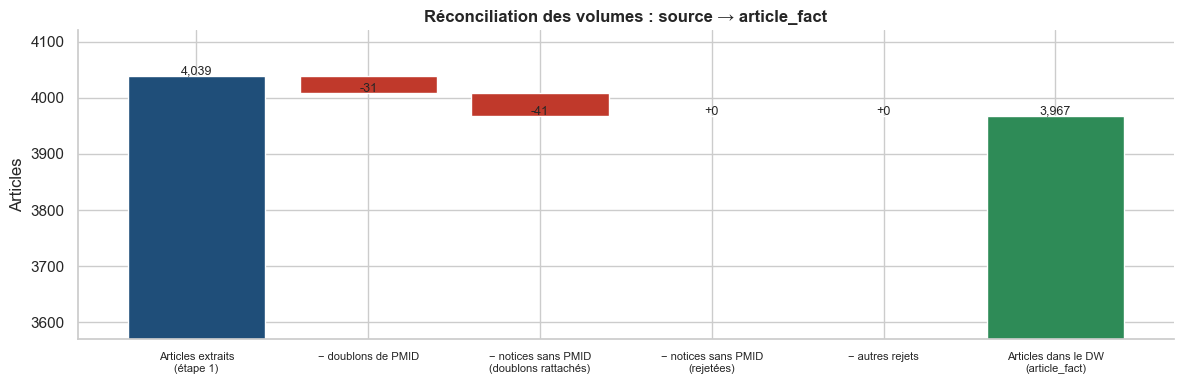

,étape,variation
0,Articles extraits (étape 1),4039
1,− doublons de PMID,-31
2,− notices sans PMID (doublons rattachés),-41
3,− notices sans PMID (rejetées),0
4,− autres rejets,0
5,Articles dans le DW (article_fact),3967


In [82]:
exp = Path("exploration_out"); extracted = len(S["art"]) + (len(pd.read_csv(exp / "F_doublons_ecartes.csv")) if (exp / "F_doublons_ecartes.csv").exists() else 0)
steps = [("Articles extraits (étape 1)", extracted), ("− doublons de PMID", -(extracted - len(S["art"]))), ("− notices sans PMID (doublons rattachés)", -len(dup_nop)),
         ("− notices sans PMID (rejetées)", -len(rest)), ("− autres rejets", -(len(S["art"]) - (extracted - extracted) - len(dup_nop) - len(rest) - len(article_fact) if False else len(S["art"]) - len(dup_nop) - len(rest) - len(article_fact)))]
wf = pd.DataFrame(steps, columns=["étape", "variation"]); wf.loc[len(wf)] = ["Articles dans le DW (article_fact)", len(article_fact)]
assert wf.variation.iloc[:-1].sum() == len(article_fact), "La réconciliation ne tombe pas juste"
cum = wf.variation.iloc[:-1].cumsum().tolist() + [len(article_fact)]
fig, ax = plt.subplots(figsize=(12, 4)); bottoms = [0] + cum[:-2] + [0]
vals = [wf.variation.iloc[0]] + [v for v in wf.variation.iloc[1:-1]] + [len(article_fact)]
colors = [C["main"]] + [C["bad"]] * (len(wf) - 2) + [C["ok"]]
ax.bar(range(len(wf)), [abs(v) if i not in (0, len(wf) - 1) else v for i, v in enumerate(vals)], bottom=[b if i not in (0, len(wf) - 1) else 0 for i, b in enumerate([0] + [cum[i - 1] + vals[i] if i else 0 for i in range(1, len(wf) - 1)] + [0])], color=colors)
ax.set_xticks(range(len(wf))); ax.set_xticklabels([s.replace(" (", "\n(") for s in wf.étape], fontsize=8); ax.set(title="Réconciliation des volumes : source → article_fact", ylabel="Articles", ylim=(len(article_fact) * .9, extracted * 1.02))
for i, v in enumerate(vals): ax.text(i, (cum[i] if 0 < i < len(wf) - 1 else v) + 3, f"{v:+,}" if 0 < i < len(wf) - 1 else f"{v:,}", ha="center", fontsize=9)
plt.tight_layout(); plt.show(); wf

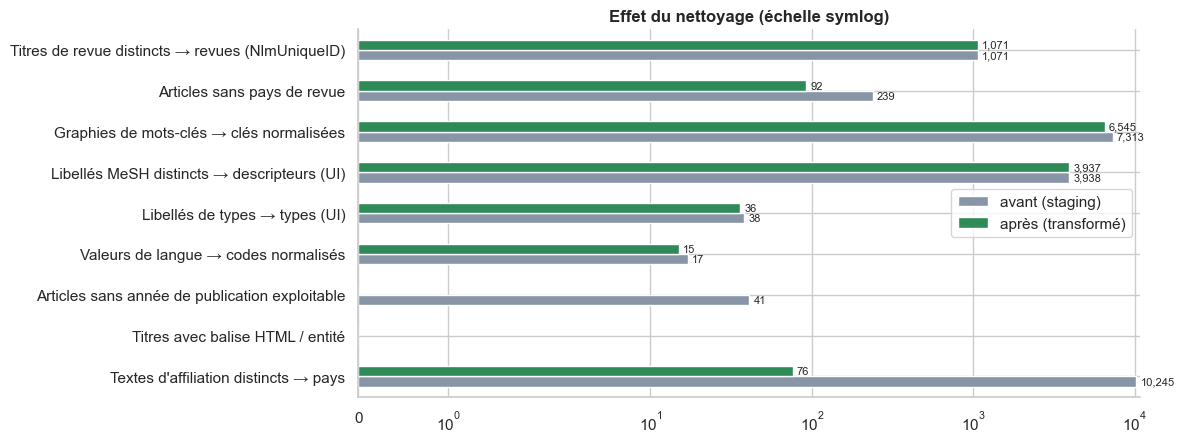

,avant (staging),après (transformé)
indicateur,,
Titres de revue distincts → revues (NlmUniqueID),"1,071","1,071"
Articles sans pays de revue,239,92
Graphies de mots-clés → clés normalisées,"7,313","6,545"
Libellés MeSH distincts → descripteurs (UI),"3,938","3,937"
Libellés de types → types (UI),38,36
Valeurs de langue → codes normalisés,17,15
Articles sans année de publication exploitable,41,0
Titres avec balise HTML / entité,0,0
Textes d'affiliation distincts → pays,"10,245",76


In [83]:
before_after = pd.DataFrame([
    ("Titres de revue distincts → revues (NlmUniqueID)", S["art"].revue.nunique(), len(revue)),
    ("Articles sans pays de revue", int(S["art"].pays_revue.isna().sum()), int(article_large.nlm_id.map(revue.set_index("nlm_id").pays_editeur).isna().sum())),
    ("Graphies de mots-clés → clés normalisées", S["mots_cles"].mot_cle.nunique(), len(motcle_dim)),
    ("Libellés MeSH distincts → descripteurs (UI)", S["mesh"].descripteur.nunique(), len(mesh_dim)),
    ("Libellés de types → types (UI)", S["types_pub"].type.nunique(), len(type_dim)),
    ("Valeurs de langue → codes normalisés", S["langues"].langue.nunique(), len(langue_dim) - 1),
    ("Articles sans année de publication exploitable", int(S["art"].pub_annee_eff.isna().sum()), int(article_large.annee_pub.isna().sum())),
    ("Titres avec balise HTML / entité", int(S["art"].titre.str.contains(r"</?[A-Za-z][^>]*>|&(?:amp|lt|gt|quot);", regex=True, na=False).sum()), int(article_large.titre.str.contains(r"</?[A-Za-z][^>]*>|&(?:amp|lt|gt|quot);", regex=True, na=False).sum())),
    ("Textes d'affiliation distincts → pays", af.affiliation.nunique(), len(pays_dim) - 1),
], columns=["indicateur", "avant (staging)", "après (transformé)"]).set_index("indicateur")
fig, ax = plt.subplots(figsize=(12, 4.6)); before_after.iloc[::-1].plot.barh(color=[C["grey"], C["ok"]], ax=ax); ax.set_xscale("symlog"); show_bar_labels(ax, horizontal=True)
ax.set(title="Effet du nettoyage (échelle symlog)", xlabel="", ylabel=""); plt.tight_layout(); plt.show()
before_after.style.format("{:,}")

---
# T14 — Registre des règles (L03), rejets, dictionnaire de données, export

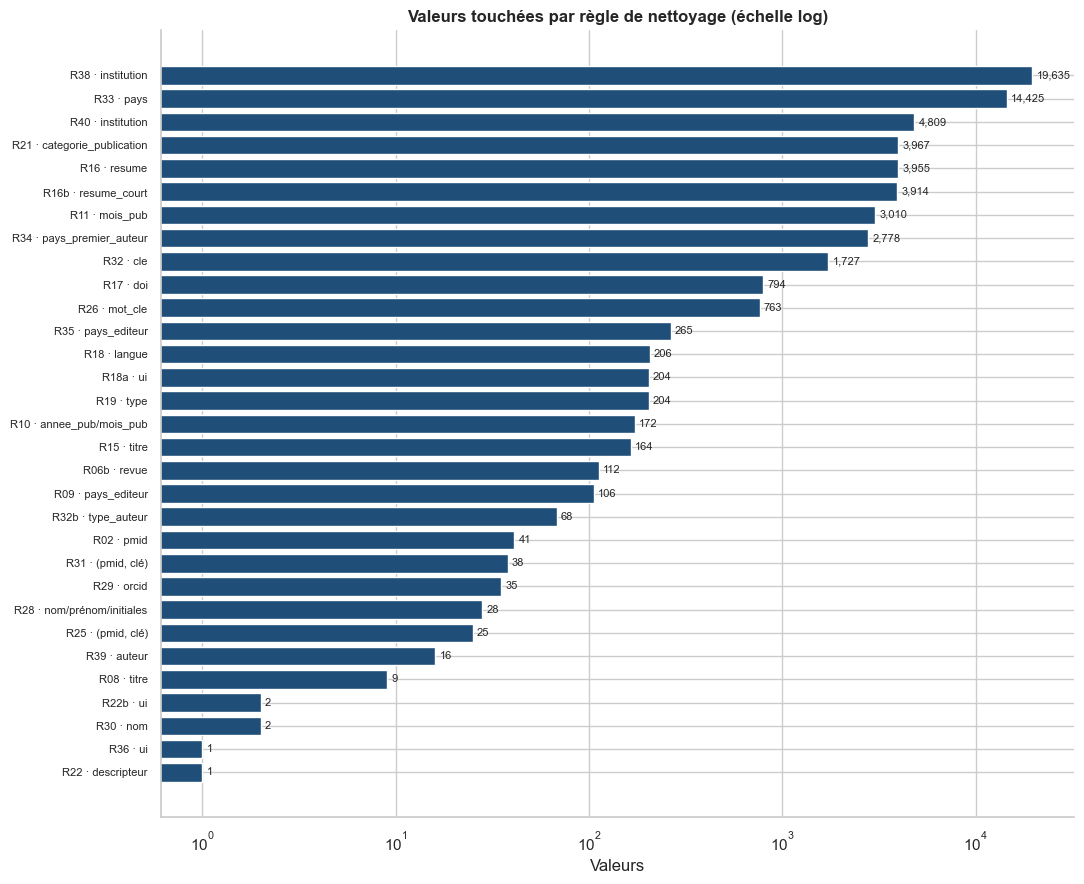

règle,table,colonne,description,valeurs_modifiées,base,pct
R01,article,pmid,PMID non numérique → rejeté,0,"4,008",0.0
R02,article,pmid,Notice sans PMID retrouvée (titre/DOI) = doublon d'un article existant → écartée,41,41,100.0
R03,article,pmid,Notice sans PMID ni correspondance → rejetée (pas de clé métier),0,41,0.0
R04b,article,titre,Article sans titre → rejeté (notice inexploitable),0,"3,967",0.0
R05,article,nlm_id,NlmUniqueID au format invalide → NULL,0,"3,966",0.0
R06,article,revue,"Titre de revue : trim, espaces multiples, caractères invisibles",0,"3,967",0.0
R06b,article,revue,Accents isolés (´ ¨ ` ~) recomposés dans le titre de revue,112,"3,967",2.8
R07,article,issn,issn au format invalide → NULL,0,"3,961",0.0
R07,article,issn_liaison,issn_liaison au format invalide → NULL,0,"3,872",0.0
R08,article→revue,titre,"Titre de revue unifié par NlmUniqueID (variante la plus fréquente, sans caractère suspect)",9,"3,966",0.2


In [84]:
rules = pd.DataFrame(RULES).sort_values("règle").reset_index(drop=True)
rules.to_csv(OUT / "registre_regles_nettoyage.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(REJETS).to_csv(OUT / "rejets.csv", index=False, encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11, 9)); r_ = rules[rules.valeurs_modifiées > 0].sort_values("valeurs_modifiées")
ax.barh(r_.règle + " · " + r_.colonne.str[:22], r_.valeurs_modifiées, color=C["main"]); ax.set_xscale("log"); show_bar_labels(ax, horizontal=True)
ax.set(title="Valeurs touchées par règle de nettoyage (échelle log)", xlabel="Valeurs"); ax.tick_params(axis="y", labelsize=8); plt.tight_layout(); plt.show()
(rules.style.format({"pct": "{:.1f}", "valeurs_modifiées": "{:,}", "base": "{:,}"}).bar(subset=["pct"], color="#bfe3c9", vmin=0, vmax=100).hide(axis="index"))

In [85]:
DESC = {"article_key": "Clé de substitution de la publication", "revue_key": "Clé étrangère → revue_dim", "temps_pub_key": "Clé étrangère → temps_dim : date de publication (AAAAMM00 ; AAAA0000 si le mois est inconnu)",
        "temps_creation_key": "Clé étrangère → temps_dim : date de création de la notice (AAAAMMJJ)", "categorie_key": "Clé étrangère → categorie_dim", "statut_key": "Clé étrangère → statut_dim",
        "langue_key": "Clé étrangère → langue_dim (langue principale)", "pays_premier_auteur_key": "Clé étrangère → pays_dim : pays du 1ᵉʳ auteur (0 = non renseigné)", "pays_key": "Clé de substitution du pays (ou clé étrangère)",
        "nb_auteurs": "Mesure : auteurs individuels + collectifs après dédoublonnage", "nb_collectifs": "Mesure : dont auteurs collectifs",
        "nb_mesh": "Mesure : descripteurs MeSH distincts", "nb_mesh_majeurs": "Mesure : descripteurs MeSH majeurs", "nb_mots_cles": "Mesure : mots-clés distincts", "nb_pays": "Mesure : pays distincts des affiliations",
        "mots_titre": "Mesure : nombre de mots du titre", "mots_resume": "Mesure : nombre de mots du résumé d'origine (0 si absent)",
        "pmid": "Identifiant PubMed (clé métier)", "titre": "Titre nettoyé (sans balises ni crochets de traduction)", "titre_traduit": "Le titre d'origine était une traduction « [..] »", "doi": "DOI normalisé",
        "resume_court": "Résumé raccourci par NLP extractif (phrases les plus représentatives, ordre d'origine)", "a_resume": "Un résumé existait dans la notice", "est_indexe_mesh": "Article indexé MeSH",
        "source_date_pub": "Origine de la date de publication : PubDate / MedlineDate / Saison", "source_fichier": "Fichier XML d'origine (traçabilité)", "niveau_reparation": "Niveau de parsing (L0 = intact)",
        "nlm_id": "Identifiant NLM de la revue (clé métier)", "abrev": "Abréviation MedlineTA", "issn": "ISSN", "issn_liaison": "ISSN de liaison (ISSN-L, champ officiel PubMed)",
        "annee": "Année", "mois": "Mois (1–12)", "jour": "Jour", "niveau": "Précision de la date : Jour / Mois / Année / Inconnu", "libelle_mois": "Nom du mois", "trimestre": "Trimestre (1–4)",
        "categorie": "Catégorie principale dérivée des types de publication", "statut_citation": "Statut de la citation (MEDLINE, PubMed-not-MEDLINE, …)", "code_langue": "Code de langue ISO 639-2", "libelle": "Libellé",
        "pays": "Nom du pays (anglais)", "cle_auteur": "Clé métier de l'auteur (nom|initiales ou collectif|nom)", "type_auteur": "Individuel ou Collectif", "nom": "Nom de famille (individuel) ou nom du groupe (collectif)",
        "prenom_frequent": "Prénom le plus fréquent (individuel)", "initiales": "Initiales (individuel)", "orcid": "ORCID normalisé", "nb_prenoms_distincts": "Prénoms distincts sous la même clé (> 1 : homonymes possibles)",
        "ui_mesh": "Identifiant MeSH (UI)", "descripteur": "Descripteur MeSH canonique", "est_geographique": "Descripteur de type géographique", "cle_motcle": "Clé normalisée du mot-clé",
        "ui_type": "Identifiant du type de publication (UI)", "rang": "Rang de l'auteur dans la notice", "est_premier": "1 = premier auteur", "est_dernier": "1 = dernier auteur", "majeur": "1 = descripteur MeSH majeur", "nb_substances": "Mesure : substances chimiques distinctes", "nb_institutions": "Mesure : institutions distinctes (extraites des affiliations)", "ui_substance": "Identifiant MeSH de la substance (UI)",
        "registre": "Numéro de registre (CAS / EC) ; NULL si absent", "substance": "Nom de la substance", "cle_institution": "Clé normalisée de l'institution", "institution_key": "Clé étrangère → institution_dim", "substance_key": "Clé de substitution / étrangère de la substance", "auteur_key": "Clé étrangère → auteur_dim", "est_principale": "1 = langue principale"}
DESC_T = {("article_fact", "nb_publications"): "Mesure : 1 par publication (somme = nombre de publications)", ("revue_dim", "pays_key"): "Clé étrangère → pays_dim (sous-dimension : pays de l'éditeur ; 0 = non renseigné)",
          ("auteur_dim", "nb_publications"): "Nombre de publications de l'auteur", ("motcle_dim", "nb_publications"): "Nombre de publications utilisant ce mot-clé", ("pays_dim", "pays_key"): "Clé de substitution du pays"}
def role(t, c):
    if c == KEYS.get(t): return "Clé primaire"
    if c.endswith("_key"): return "Clé étrangère"
    if t == "article_fact": return "Mesure"
    return "Attribut du lien" if t.endswith("_bridge") else "Attribut"
dico = pd.DataFrame([dict(table=t, colonne=c, rôle=role(t, c), type=str(df[c].dtype), pct_null=100 * df[c].isna().mean(), distincts=df[c].nunique(), description=DESC_T.get((t, c), DESC.get(c, ""))) for t, df in DW.items() for c in df.columns])
dico.to_csv(OUT / "dictionnaire_donnees.csv", index=False, encoding="utf-8-sig")
for t, df in DW.items(): df.to_csv(OUT / "dw_tables" / f"{t}.csv", index=False, encoding="utf-8")
print(f"{len(DW)} tables exportées dans {OUT/'dw_tables'} · registre : {len(rules)} règles · rejets : {len(REJETS)} lignes tracées")
dico[dico.table == "article_fact"].set_index("colonne").style.format({"pct_null": "{:.1f}"})


22 tables exportées dans transform_out\dw_tables · registre : 47 règles · rejets : 46 lignes tracées


,table,rôle,type,pct_null,distincts,description
colonne,,,,,,
article_key,article_fact,Clé étrangère,int64,0.0,3967,Clé de substitution de la publication
revue_key,article_fact,Clé étrangère,int64,0.0,1071,Clé étrangère → revue_dim
temps_pub_key,article_fact,Clé étrangère,int64,0.0,49,Clé étrangère → temps_dim : date de publication (AAAAMM00 ; AAAA0000 si le mois est inconnu)
temps_creation_key,article_fact,Clé étrangère,int64,0.0,558,Clé étrangère → temps_dim : date de création de la notice (AAAAMMJJ)
categorie_key,article_fact,Clé étrangère,int64,0.0,8,Clé étrangère → categorie_dim
statut_key,article_fact,Clé étrangère,int64,0.0,5,Clé étrangère → statut_dim
langue_key,article_fact,Clé étrangère,int64,0.0,14,Clé étrangère → langue_dim (langue principale)
pays_premier_auteur_key,article_fact,Clé étrangère,int64,0.0,62,Clé étrangère → pays_dim : pays du 1ᵉʳ auteur (0 = non renseigné)
nb_publications,article_fact,Mesure,int64,0.0,1,Mesure : 1 par publication (somme = nombre de publications)


On parcourt toutes les tables contenues dans DW et on exporte chacune dans un fichier CSV indépendant.

# 🧾 Bilan de l'étape 2

* **Modèle en flocon** : 1 table de faits `article_fact` (1 ligne = 1 publication ;
  clés étrangères entières et mesures uniquement), des dimensions, des sous-dimensions
  et des tables de liaison (factless fact tables).
* **Dimensions** : le texte (titre, DOI, **résumé court**, statut, catégorie, revue,
  langue, pays du 1ᵉʳ auteur) est dans les dimensions ; `auteur_dim` regroupe
  **personnes et auteurs collectifs** (`type_auteur`) ; `temps_dim` joue **deux rôles**
  (date de publication + date de création de la notice).
* **Sous-dimensions** (hiérarchies du flocon) : `pays_dim` est **sous-dimension de
  `revue_dim`** (pays de l'éditeur) et **de `institution_dim`** (pays de l'institution).
  Ce sont les **seuls liens directs dim→dim** du modèle — et ce ne sont pas des
  relations entre pairs, mais des hiérarchies (niveau inférieur).
* **Tables de liaison** (factless fact tables) : les **8 tables** `article_auteur_bridge`,
  `article_mesh_bridge`, `article_motcle_bridge`, `article_type_bridge`, `article_langue_bridge`,
  `article_pays_bridge`, `article_substance_bridge` et `article_institution_bridge`
  matérialisent les relations N-N **au grain de `article_fact`** (via `article_key`) —
  **jamais entre deux dimensions de même niveau**. `article_institution_bridge` est
  **ternaire** (`article_key`, `auteur_key`, `institution_key`) car une institution est
  rattachée à un couple (article, auteur), pas à un article seul.
* **Clé métier** : PMID unique, 100 % renseigné ; les notices sans PMID sont rattachées
  par titre/DOI ou rejetées (tracées dans `rejets.csv`).
* **Fiabilité** : tous les contrôles d'intégrité passent, la réconciliation
  source → `article_fact` tombe juste, le registre des règles (L03) et le dictionnaire
  de données sont exportés.

## ➡️ Étape 3 : chargement du Data Warehouse

Les tables de `transform_out/dw_tables/` portent déjà leurs clés de substitution.
L'ordre de chargement respecte les dépendances FK :
**`pays_dim` → dimensions qui en dépendent (`revue_dim`, `institution_dim`) →
autres dimensions → `article_dim` → tables de liaison → `article_fact`**,
avec vérification des volumes et des contraintes PK/FK (chargement idempotent).

❓ **Une question avant de coder :** quel SGBD pour le Data Warehouse ?
Le cahier des charges recommandait **PostgreSQL** ; si tu n'as pas d'instance
disponible, **SQLite** produit le même schéma et reste lisible par Power BI via
un connecteur ODBC.